**Chapter 1 – The Machine Learning landscape**

_This is the code used to generate some of the figures in chapter 1._

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/ageron/handson-ml2/blob/master/01_the_machine_learning_landscape.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/ageron/handson-ml2/blob/master/01_the_machine_learning_landscape.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

# Code example 1-1

Although Python 2.x may work, it is deprecated so we strongly recommend you use Python 3 instead.

In [75]:
# Beginner explanation: This is already a comment written by the original author; Python ignores it when running the code.
# Python ≥3.5 is required
# Beginner explanation: This imports the Python library/module `sys` so we can use its ready-made functions in this notebook.
import sys
# Beginner explanation: This checks that a condition is true; if it is false, Python stops and shows an error.
assert sys.version_info >= (3, 5)

In [76]:
# Beginner explanation: This is already a comment written by the original author; Python ignores it when running the code.
# Scikit-Learn ≥0.20 is required
# Beginner explanation: This imports the Python library/module `sklearn` so we can use its ready-made functions in this notebook.
import sklearn
# Beginner explanation: This checks that a condition is true; if it is false, Python stops and shows an error.
assert sklearn.__version__ >= "0.20"

This function just merges the OECD's life satisfaction data and the IMF's GDP per capita data. It's a bit too long and boring and it's not specific to Machine Learning, which is why I left it out of the book.

In [77]:
# Beginner explanation: This defines a reusable function named `prepare_country_stats`; the indented lines below are the steps the function performs.
def prepare_country_stats(oecd_bli, gdp_per_capita):
    #  This creates or updates the variable `oecd_bli`; a variable stores a value so we can use it later.
    oecd_bli = oecd_bli[oecd_bli["INEQUALITY"]=="TOT"]
    #  This reshapes the table: countries become rows, indicators become columns, and values fill the cells.
    oecd_bli = oecd_bli.pivot(index="Country", columns="Indicator", values="Value")
    #  This changes a column name to a clearer name that is easier to use later.
    gdp_per_capita.rename(columns={"2015": "GDP per capita"}, inplace=True)
    # This uses a column as the row label/index, making it easier to select rows by country name.
    gdp_per_capita.set_index("Country", inplace=True)
    # This combines two tables by matching their row labels, so information from both datasets appears together.
    full_country_stats = pd.merge(left=oecd_bli, right=gdp_per_capita,
                                  # This creates or updates the variable `left_index`; a variable stores a value so we can use it later.
                                  left_index=True, right_index=True)
    # This sorts the table according to one column, here to order countries by GDP per capita.
    full_country_stats.sort_values(by="GDP per capita", inplace=True)
    #  This line creates or updates the variable `remove_indices`; a variable stores a value so we can use it later.
    remove_indices = [0, 1, 6, 8, 33, 34, 35]
    #  This line creates or updates the variable `keep_indices`; a variable stores a value so we can use it later.
    keep_indices = list(set(range(36)) - set(remove_indices))
    #  This line sends the final result back to the place where the function was called.
    return full_country_stats[["GDP per capita", 'Life satisfaction']].iloc[keep_indices]

The code in the book expects the data files to be located in the current directory. I just tweaked it here to fetch the files in `datasets/lifesat`.

In [78]:
# This imports the Python library/module `os` so we can use its ready-made functions in this notebook.
import os
#  This safely builds a folder/file path using the correct separator for the operating system.
datapath = os.path.join("datasets", "lifesat", "")

In [79]:
#  This is already a comment written by the original author; Python ignores it when running the code.
# To plot pretty figures directly within Jupyter
# Beginner explanation: This Jupyter command tells the notebook to show Matplotlib graphs directly below the code cell.
%matplotlib inline
import matplotlib as mpl
#This creates or updates the variable `mpl.rc('axes', labelsize`; a variable stores a value so we can use it later.
mpl.rc('axes', labelsize=14)
# This creates or updates the variable `mpl.rc('xtick', labelsize`; a variable stores a value so we can use it later.
mpl.rc('xtick', labelsize=12)
#This creates or updates the variable `mpl.rc('ytick', labelsize`; a variable stores a value so we can use it later.
mpl.rc('ytick', labelsize=12)

In [80]:
# ============================================================
# Download the Chapter 1 datasets from my GitHub repository
# ============================================================

# The 'os' module allows Python to interact with folders and files
import os

# The 'urllib.request' module allows Python to download files from the internet
import urllib.request


# ------------------------------------------------------------
# GitHub folder that contains all dataset files
# ------------------------------------------------------------
# Instead of downloading from the original author's repository,
# we download the files from our own GitHub repository.
#
# This URL points to the folder:
# Chapter01/datasets/lifesat/
#
# Later, the file names will be appended automatically.
# For example:
# DOWNLOAD_ROOT + "lifesat.csv"
#
# becomes:
# https://raw.githubusercontent.com/.../lifesat.csv
# ------------------------------------------------------------
DOWNLOAD_ROOT = (
    "https://raw.githubusercontent.com/"
    "AT3060/handson-ml2/"
    "chapter01-life-satisfaction/"
    "Chapter01/datasets/lifesat/"
)


# ------------------------------------------------------------
# Create the local data folder if it does not already exist
# ------------------------------------------------------------
# 'datapath' is a variable defined earlier in the notebook.
#
# exist_ok=True means:
#   - If the folder already exists → do nothing.
#   - If the folder does not exist → create it.
#
# This prevents Python from raising an error.
# ------------------------------------------------------------
os.makedirs(datapath, exist_ok=True)


# ------------------------------------------------------------
# List of files that should be downloaded
# ------------------------------------------------------------
# The parentheses create a tuple containing three file names.
#
# Each file contains data used in the Life Satisfaction project:
#
# 1. oecd_bli_2015.csv
#    OECD Better Life Index indicators
#
# 2. gdp_per_capita.csv
#    GDP per capita information for countries
#
# 3. lifesat.csv
#    Processed dataset used in the chapter
# ------------------------------------------------------------
for filename in (
    "oecd_bli_2015.csv",
    "gdp_per_capita.csv",
    "lifesat.csv"
):

    # Show which file is currently being downloaded
    print("Downloading", filename)

    # Build the complete URL for the current file
    #
    # Example:
    # DOWNLOAD_ROOT =
    # https://raw.githubusercontent.com/.../lifesat/
    #
    # filename =
    # gdp_per_capita.csv
    #
    # Final URL =
    # https://raw.githubusercontent.com/.../lifesat/gdp_per_capita.csv
    url = DOWNLOAD_ROOT + filename

    # Download the file from GitHub and save it locally
    #
    # First argument:
    #   Source URL (where the file is located online)
    #
    # Second argument:
    #   Local location where the file should be saved
    #
    # Example:
    # datasets/lifesat/gdp_per_capita.csv
    urllib.request.urlretrieve(
        url,
        datapath + filename
    )


# ------------------------------------------------------------
# Inform the user that all downloads have finished
# ------------------------------------------------------------
print("All files downloaded successfully.")

All files downloaded successfully.


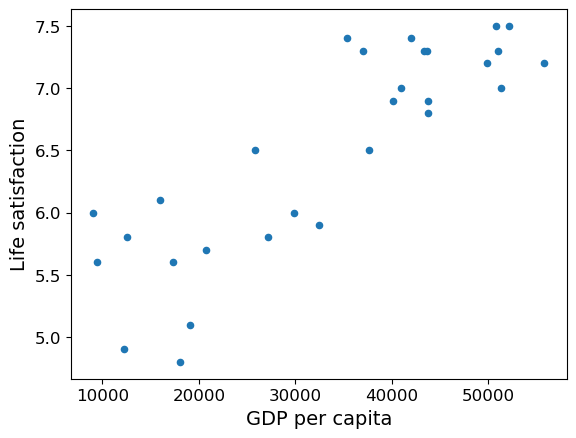

[[5.96242338]]


In [111]:
# ============================================================
# Example: Predict Life Satisfaction using GDP per Capita
# ============================================================

# ------------------------------------------------------------
# Import required libraries
# ------------------------------------------------------------

# Matplotlib is used for creating graphs and visualizations
import matplotlib.pyplot as plt

# NumPy is used for numerical computations and array operations
import numpy as np

# Pandas is used for loading, manipulating, and analyzing datasets
import pandas as pd

# Scikit-Learn contains machine learning algorithms
# Here we will use a Linear Regression model
import sklearn.linear_model


# ------------------------------------------------------------
# Load the datasets
# ------------------------------------------------------------

# Read the OECD Better Life Index dataset
#
# pd.read_csv() loads a CSV file into a Pandas DataFrame.
#
# thousands=','
# tells Pandas that commas are used as thousand separators.
#
# Example:
# "12,345" will be interpreted as the number 12345.
oecd_bli = pd.read_csv(
    datapath + "oecd_bli_2015.csv",
    thousands=','
)

# Read the GDP per capita dataset
#
# This file is slightly different from a standard CSV:
#
# delimiter='\t'
# means columns are separated by TAB characters.
#
# encoding='latin1'
# specifies the character encoding used in the file.
#
# na_values="n/a"
# tells Pandas to treat "n/a" as a missing value.
gdp_per_capita = pd.read_csv(
    datapath + "gdp_per_capita.csv",
    thousands=',',
    delimiter='\t',
    encoding='latin1',
    na_values="n/a"
)


# ------------------------------------------------------------
# Prepare the data for machine learning
# ------------------------------------------------------------

# The function prepare_country_stats()
# combines and cleans the two datasets.
#
# The output is a new table containing only the information
# needed for the machine learning experiment.
country_stats = prepare_country_stats(
    oecd_bli,
    gdp_per_capita
)

# ------------------------------------------------------------
# Create the input feature (X)
# ------------------------------------------------------------

# We want the model to learn the relationship between:
#
# GDP per capita  --->  Life satisfaction
#
# X contains the input values (GDP per capita).
#
# np.c_ converts the column into a two-dimensional array,
# which is the format expected by Scikit-Learn.
X = np.c_[country_stats["GDP per capita"]]

# ------------------------------------------------------------
# Create the target variable (y)
# ------------------------------------------------------------

# y contains the values we want the model to predict.
#
# In this example:
# Life satisfaction is the target variable.
y = np.c_[country_stats["Life satisfaction"]]


# ------------------------------------------------------------
# Visualize the data
# ------------------------------------------------------------

# Create a scatter plot.
#
# Each dot represents one country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
#
# This helps us visually inspect whether a relationship
# exists between the two variables.
country_stats.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction'
)

# Display the graph on the screen.
plt.show()


# ------------------------------------------------------------
# Create a Linear Regression model
# ------------------------------------------------------------

# Linear Regression attempts to fit a straight line through
# the data points.
#
# The model tries to learn:
#
# Life Satisfaction = a × GDP + b
#
# where:
# a = slope of the line
# b = intercept
model = sklearn.linear_model.LinearRegression()


# ------------------------------------------------------------
# Train the model
# ------------------------------------------------------------

# During training, the algorithm examines the data
# and finds the line that best fits the observed countries.
#
# X = input values (GDP per capita)
# y = target values (Life satisfaction)
model.fit(X, y)


# ------------------------------------------------------------
# Make a prediction for Cyprus
# ------------------------------------------------------------

# Cyprus has a GDP per capita of 22,587 USD.
#
# We provide this value to the trained model
# and ask it to estimate the life satisfaction score.
X_new = [[22587]]

# Generate the prediction.
prediction = model.predict(X_new)

# Print the predicted life satisfaction value.
print(prediction)

# Expected output:
# [[5.96242338]]
#
# Interpretation:
# According to the trained model,
# a country with a GDP per capita of 22,587 USD
# is expected to have a life satisfaction score
# of approximately 5.96.

In [112]:
# ============================================================
# Replacing Linear Regression with k-Nearest Neighbors (k-NN)
# ============================================================

# ------------------------------------------------------------
# In the previous example, we used Linear Regression:
#
# import sklearn.linear_model
# model = sklearn.linear_model.LinearRegression()
#
# Linear Regression tries to find a single straight line
# that best fits all data points.
#
# The model learns an equation of the form:
#
# Life Satisfaction = a × GDP per capita + b
#
# Once trained, predictions are made using this line.
# ------------------------------------------------------------


# ------------------------------------------------------------
# Now we replace Linear Regression with a k-Nearest Neighbors
# (k-NN) Regression model.
#
# Unlike Linear Regression, k-NN does NOT learn a mathematical
# equation during training.
#
# Instead, when a prediction is requested, it looks for
# countries with similar GDP values and uses their life
# satisfaction scores to estimate the result.
# ------------------------------------------------------------


# Import the k-Nearest Neighbors module from Scikit-Learn
import sklearn.neighbors


# ------------------------------------------------------------
# Create a k-NN Regression model
# ------------------------------------------------------------
#
# n_neighbors = 3 means:
#
# For every new GDP value:
#   1. Find the 3 countries whose GDP per capita values are
#      closest to the new GDP value.
#
#   2. Look at their life satisfaction scores.
#
#   3. Compute the average of those scores.
#
#   4. Return the average as the prediction.
#
# Example:
#
# Suppose the 3 nearest countries have:
#
# Country A -> Life Satisfaction = 5.8
# Country B -> Life Satisfaction = 6.0
# Country C -> Life Satisfaction = 6.2
#
# Prediction:
#
# (5.8 + 6.0 + 6.2) / 3 = 6.0
#
# Therefore the model predicts 6.0.
#
# Notice that k-NN relies directly on existing examples
# rather than learning a formula.
# ------------------------------------------------------------
model = sklearn.neighbors.KNeighborsRegressor(
    n_neighbors=3
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
#
# Linear Regression:
# ------------------
# • Learns a straight-line equation.
# • Fast predictions.
# • Assumes a linear relationship.
#
# k-Nearest Neighbors Regression:
# -------------------------------
# • Does not learn a formula.
# • Uses nearby examples to make predictions.
# • Can model more complex relationships.
# • Prediction can be slower because it searches
#   through the training data each time.
#
# In this example:
#
# k = 3
#
# meaning the model uses the 3 nearest countries
# when estimating life satisfaction.
# ------------------------------------------------------------

In [113]:
# Select a 3-Nearest Neighbors regression model
import sklearn.neighbors
model1 = sklearn.neighbors.KNeighborsRegressor(n_neighbors=3)

# Train the model
model1.fit(X,y)

# Make a prediction for Cyprus
print(model1.predict(X_new)) # outputs [[5.76666667]]


[[5.76666667]]


# Note: you can ignore the rest of this notebook, it just generates many of the figures in chapter 1.

Create a function to save the figures.

In [142]:
# ============================================================
# Configure where generated figures will be stored
# ============================================================

# ------------------------------------------------------------
# PROJECT_ROOT_DIR represents the root folder of the project.
#
# "." means:
# "the current working directory"
#
# Example:
#
# If the notebook is located in:
#
# C:/Projects/handson-ml2/Chapter01/
#
# then "." refers to:
#
# C:/Projects/handson-ml2/Chapter01/
# ------------------------------------------------------------
PROJECT_ROOT_DIR = "."


# ------------------------------------------------------------
# Name of the chapter or topic.
#
# This name will be used when creating folders
# for storing images.
#
# In this case, all figures generated in this chapter
# will be saved inside a folder called "fundamentals".
# ------------------------------------------------------------
CHAPTER_ID = "fundamentals"


# ------------------------------------------------------------
# Build the complete path where figures will be saved.
#
# os.path.join() safely combines folder names
# regardless of the operating system.
#
# Instead of manually writing:
#
# "images/fundamentals"
#
# Python constructs the path automatically.
#
# Result:
#
# images/fundamentals
#
# Windows:
# images\fundamentals
#
# Linux/Mac:
# images/fundamentals
# ------------------------------------------------------------
IMAGES_PATH = os.path.join(
    PROJECT_ROOT_DIR,
    "images",
    CHAPTER_ID
)


# ------------------------------------------------------------
# Create the image folder if it does not already exist.
#
# exist_ok=True means:
#
# - If the folder already exists → do nothing.
# - If the folder does not exist → create it.
#
# This prevents an error from occurring.
# ------------------------------------------------------------
os.makedirs(
    IMAGES_PATH,
    exist_ok=True
)


# ============================================================
# Function: save_fig()
# ============================================================
#
# A function is a reusable block of code.
#
# Instead of repeatedly writing:
#
# plt.tight_layout()
# plt.savefig(...)
#
# we create one function and call it whenever
# we want to save a figure.
#
# Example:
#
# save_fig("my_plot")
#
# will save the current figure automatically.
# ============================================================

def save_fig(
    fig_id,
    tight_layout=True,
    fig_extension="png",
    resolution=300
):
    """
    Save the current Matplotlib figure to disk.

    Parameters
    ----------
    fig_id : str
        Name of the figure file.

    tight_layout : bool
        Whether to automatically adjust spacing
        between plot elements.

    fig_extension : str
        File format to save.
        Examples:
        png, jpg, pdf, svg

    resolution : int
        Image quality measured in DPI
        (dots per inch).
    """

    # --------------------------------------------------------
    # Construct the complete file path.
    #
    # Example:
    #
    # IMAGES_PATH =
    # images/fundamentals
    #
    # fig_id =
    # life_satisfaction_scatterplot
    #
    # fig_extension =
    # png
    #
    # Result:
    #
    # images/fundamentals/life_satisfaction_scatterplot.png
    # --------------------------------------------------------
    path = os.path.join(
        IMAGES_PATH,
        fig_id + "." + fig_extension
    )

    # Display a message so the user knows
    # which figure is being saved.
    print("Saving figure", fig_id)

    # --------------------------------------------------------
    # Automatically improve the layout.
    #
    # tight_layout() reduces overlapping labels,
    # titles, and axis text.
    #
    # This makes the figure look cleaner.
    # --------------------------------------------------------
    if tight_layout:
        plt.tight_layout()

    # --------------------------------------------------------
    # Save the current figure to the file path.
    #
    # path:
    #   Where the file will be stored.
    #
    # format:
    #   File type (png, jpg, pdf, etc.)
    #
    # dpi:
    #   Resolution of the image.
    #
    # Common values:
    #
    # 72   -> screen quality
    # 150  -> decent quality
    # 300  -> publication quality
    # --------------------------------------------------------
    plt.savefig(
        path,
        format=fig_extension,
        dpi=resolution
    )

Make this notebook's output stable across runs:

In [115]:
np.random.seed(42)

# Load and prepare Life satisfaction data

If you want, you can get fresh data from the OECD's website.
Download the CSV from http://stats.oecd.org/index.aspx?DataSetCode=BLI
and save it to `datasets/lifesat/`.

In [144]:
# ============================================================
# Load and prepare the OECD Better Life Index dataset
# ============================================================

# ------------------------------------------------------------
# Step 1: Load the CSV file into a Pandas DataFrame
# ------------------------------------------------------------
#
# pd.read_csv() reads a CSV file and stores it in a table-like
# structure called a DataFrame.
#
# thousands=','
# tells Pandas that commas are used as thousand separators.
#
# Example:
#
# "12,345"
#
# will be interpreted as:
#
# 12345
#
# rather than as text.
# ------------------------------------------------------------
oecd_bli = pd.read_csv(
    datapath + "oecd_bli_2015.csv",
    thousands=','
)


# ------------------------------------------------------------
# Step 2: Keep only rows corresponding to the total population
# ------------------------------------------------------------
#
# The OECD dataset contains statistics for different groups:
#
# TOT  -> Total population
# MN   -> Men
# WMN  -> Women
#
# For this project, we only want the overall values for each
# country, so we keep rows where:
#
# INEQUALITY == "TOT"
#
# Example:
#
# Germany, Men, Income
# Germany, Women, Income
# Germany, Total, Income   ← keep this one
#
# All other rows are removed.
# ------------------------------------------------------------
oecd_bli = oecd_bli[
    oecd_bli["INEQUALITY"] == "TOT"
]


# ------------------------------------------------------------
# Step 3: Reshape the table using a pivot operation
# ------------------------------------------------------------
#
# The original dataset is stored in a "long" format.
#
# Example:
#
# Country     Indicator               Value
# Germany     Life Satisfaction       6.8
# Germany     Income                  31252
# Germany     Employment Rate         74
#
# This format is not convenient for machine learning.
#
# We convert it into a "wide" format:
#
# Country     Life Satisfaction   Income   Employment Rate
# Germany           6.8           31252          74
#
# Each country becomes one row.
# Each indicator becomes a column.
#
# Parameters:
#
# index="Country"
#   Countries become row labels.
#
# columns="Indicator"
#   Indicator names become column names.
#
# values="Value"
#   Numerical values fill the table cells.
# ------------------------------------------------------------
oecd_bli = oecd_bli.pivot(
    index="Country",
    columns="Indicator",
    values="Value"
)


# ------------------------------------------------------------
# Step 4: Display the first two rows of the transformed table
# ------------------------------------------------------------
#
# head(n) shows the first n rows.
#
# head(2) means:
# "Show only the first two countries."
#
# This is useful for quickly checking whether the data
# was loaded and transformed correctly.
#
# Example output:
#
# Country      Life Satisfaction   Income   Employment
# Australia          7.3          31588        72
# Austria            6.9          31173        72
#
# (Actual values may differ.)
# ------------------------------------------------------------
oecd_bli.head(5)

Indicator,Air pollution,Assault rate,Consultation on rule-making,Dwellings without basic facilities,Educational attainment,Employees working very long hours,Employment rate,Homicide rate,Household net adjusted disposable income,Household net financial wealth,...,Long-term unemployment rate,Personal earnings,Quality of support network,Rooms per person,Self-reported health,Student skills,Time devoted to leisure and personal care,Voter turnout,Water quality,Years in education
Country,,,,,,,,,,,,,,,,,,,,,
Australia,13.0,2.1,10.5,1.1,76.0,14.02,72.0,0.8,31588.0,47657.0,...,1.08,50449.0,92.0,2.3,85.0,512.0,14.41,93.0,91.0,19.4
Austria,27.0,3.4,7.1,1.0,83.0,7.61,72.0,0.4,31173.0,49887.0,...,1.19,45199.0,89.0,1.6,69.0,500.0,14.46,75.0,94.0,17.0
Belgium,21.0,6.6,4.5,2.0,72.0,4.57,62.0,1.1,28307.0,83876.0,...,3.88,48082.0,94.0,2.2,74.0,509.0,15.71,89.0,87.0,18.9
Brazil,18.0,7.9,4.0,6.7,45.0,10.41,67.0,25.5,11664.0,6844.0,...,1.97,17177.0,90.0,1.6,69.0,402.0,14.97,79.0,72.0,16.3
Canada,15.0,1.3,10.5,0.2,89.0,3.94,72.0,1.5,29365.0,67913.0,...,0.90,46911.0,92.0,2.5,89.0,522.0,14.25,61.0,91.0,17.2


In [117]:
oecd_bli["Life satisfaction"].head()
# Display the first 5 entries
# ------------------------------------------------------------
#
# head()
#
# returns the first 5 rows by default.
#
# It is commonly used to quickly inspect data
# without displaying the entire dataset.

Country
Australia    7.3
Austria      6.9
Belgium      6.9
Brazil       7.0
Canada       7.3
Name: Life satisfaction, dtype: float64

# Load and prepare GDP per capita data

Just like above, you can update the GDP per capita data if you want. Just download data from http://goo.gl/j1MSKe (=> imf.org) and save it to `datasets/lifesat/`.

In [146]:
# ============================================================
# Load and prepare the GDP per Capita dataset
# ============================================================

# ------------------------------------------------------------
# Step 1: Load the GDP dataset from a CSV file
# ------------------------------------------------------------
#
# pd.read_csv() reads the file and stores it in a
# Pandas DataFrame.
#
# This dataset is not a standard comma-separated CSV,
# so several additional parameters are required.
#
# thousands=','
#   Tells Pandas that commas are used as thousand
#   separators in numerical values.
#
# delimiter='\t'
#   Indicates that columns are separated by TAB
#   characters rather than commas.
#
# encoding='latin1'
#   Specifies the character encoding used in the file.
#   This helps Pandas correctly read special characters.
#
# na_values="n/a"
#   Treats the text "n/a" as a missing value (NaN).
#
# Missing values are important because mathematical
# operations cannot be performed directly on text such
# as "n/a".
# ------------------------------------------------------------
gdp_per_capita = pd.read_csv(
    datapath + "gdp_per_capita.csv",
    thousands=',',
    delimiter='\t',
    encoding='latin1',
    na_values="n/a"
)


# ------------------------------------------------------------
# Step 2: Rename the column "2015"
# ------------------------------------------------------------
#
# The dataset contains a column named "2015".
#
# Example:
#
# Country        2015
# Germany       43742
# France        37675
#
# The name "2015" is not very descriptive.
#
# We rename it to:
#
# "GDP per capita"
#
# which makes the dataset easier to understand.
#
# columns={old_name: new_name}
#
# inplace=True
# means:
#   Modify the existing DataFrame directly.
#
# Without inplace=True, Pandas would create a new
# DataFrame and leave the original unchanged.
# ------------------------------------------------------------
gdp_per_capita.rename(
    columns={"2015": "GDP per capita"},
    inplace=True
)


# ------------------------------------------------------------
# Step 3: Set the Country column as the index
# ------------------------------------------------------------
#
# By default, Pandas assigns numerical row numbers:
#
# 0
# 1
# 2
# ...
#
# However, countries are a much better identifier.
#
# Before:
#
#     Country      GDP per capita
# 0   Germany          43742
# 1   France           37675
#
# After:
#
# Country
# Germany             43742
# France              37675
#
# This makes it easier to locate information
# for a specific country.
#
# inplace=True means:
# modify the existing DataFrame directly.
# ------------------------------------------------------------
gdp_per_capita.set_index(
    "Country",
    inplace=True
)


# ------------------------------------------------------------
# Step 4: Display the first two rows
# ------------------------------------------------------------
#
# head(2) returns only the first two rows.
#
# This is useful for quickly checking whether:
#
# ✓ The file loaded correctly
# ✓ The column was renamed correctly
# ✓ The country names became the index
#
# Example output:
#
#                GDP per capita
# Country
# Australia           50961
# Austria             43724
#
# (Actual values may differ.)
# ------------------------------------------------------------
gdp_per_capita.head(5)

,Subject Descriptor,Units,Scale,Country/Series-specific Notes,GDP per capita,Estimates Start After
Country,,,,,,
Afghanistan,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",599.994,2013.0
Albania,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",3995.383,2010.0
Algeria,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",4318.135,2014.0
Angola,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",4100.315,2014.0
Antigua and Barbuda,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",14414.302,2011.0


In [119]:
full_country_stats = pd.merge(left=oecd_bli, right=gdp_per_capita, left_index=True, right_index=True)
full_country_stats.sort_values(by="GDP per capita", inplace=True)
full_country_stats

,Air pollution,Assault rate,Consultation on rule-making,Dwellings without basic facilities,Educational attainment,Employees working very long hours,Employment rate,Homicide rate,Household net adjusted disposable income,Household net financial wealth,...,Time devoted to leisure and personal care,Voter turnout,Water quality,Years in education,Subject Descriptor,Units,Scale,Country/Series-specific Notes,GDP per capita,Estimates Start After
Country,,,,,,,,,,,,,,,,,,,,,
Brazil,18.0,7.9,4.0,6.7,45.0,10.41,67.0,25.5,11664.0,6844.0,...,14.97,79.0,72.0,16.3,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",8669.998,2014.0
Mexico,30.0,12.8,9.0,4.2,37.0,28.83,61.0,23.4,13085.0,9056.0,...,13.89,63.0,67.0,14.4,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",9009.280,2015.0
Russia,15.0,3.8,2.5,15.1,94.0,0.16,69.0,12.8,19292.0,3412.0,...,14.97,65.0,56.0,16.0,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",9054.914,2015.0
Turkey,35.0,5.0,5.5,12.7,34.0,40.86,50.0,1.2,14095.0,3251.0,...,13.42,88.0,62.0,16.4,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",9437.372,2013.0
Hungary,15.0,3.6,7.9,4.8,82.0,3.19,58.0,1.3,15442.0,13277.0,...,15.04,62.0,77.0,17.6,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",12239.894,2015.0
Poland,33.0,1.4,10.8,3.2,90.0,7.41,60.0,0.9,17852.0,10919.0,...,14.20,55.0,79.0,18.4,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",12495.334,2014.0
Chile,46.0,6.9,2.0,9.4,57.0,15.42,62.0,4.4,14533.0,17733.0,...,14.41,49.0,73.0,16.5,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",13340.905,2014.0
Slovak Republic,13.0,3.0,6.6,0.6,92.0,7.02,60.0,1.2,17503.0,8663.0,...,14.99,59.0,81.0,16.3,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",15991.736,2015.0
Czech Republic,16.0,2.8,6.8,0.9,92.0,6.98,68.0,0.8,18404.0,17299.0,...,14.98,59.0,85.0,18.1,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",17256.918,2015.0


In [120]:
full_country_stats[["GDP per capita", 'Life satisfaction']].loc["United States"]

GDP per capita       55805.204
Life satisfaction        7.200
Name: United States, dtype: float64

In [148]:
# ============================================================
# Separate the dataset into:
#   1. Sample data used for training/visualization
#   2. Missing data used for demonstration purposes
# ============================================================

# ------------------------------------------------------------
# Step 1: Define the row indices that should be removed
# ------------------------------------------------------------
#
# Each row in the DataFrame has a numerical position:
#
# 0, 1, 2, 3, 4, ...
#
# The author of the book intentionally removes some
# countries from the dataset.
#
# These countries will later be treated as
# "missing countries".
#
# The numbers below represent the row positions
# of the countries that should be excluded.
#
# Example:
#
# Row 0  -> remove
# Row 1  -> remove
# Row 2  -> keep
# Row 3  -> keep
# ...
#
# The exact countries can be inspected later.
# ------------------------------------------------------------
remove_indices = [0, 1, 6, 8, 33, 34, 35]


# ------------------------------------------------------------
# Step 2: Determine which rows should be kept
# ------------------------------------------------------------
#
# range(36)
#
# creates numbers from:
#
# 0, 1, 2, ..., 35
#
# because there are 36 countries in the dataset.
#
# set(range(36))
#
# creates a set containing all row indices.
#
# set(remove_indices)
#
# creates a set containing only the rows
# we want to remove.
#
# The subtraction operation:
#
# all rows - removed rows
#
# leaves only the rows we want to keep.
#
# Example:
#
# All rows:
# {0,1,2,3,4,5}
#
# Removed rows:
# {0,2}
#
# Result:
# {1,3,4,5}
#
# Finally, list(...)
# converts the result back into a Python list.
# ------------------------------------------------------------
keep_indices = list(
    set(range(36)) - set(remove_indices)
)


# ------------------------------------------------------------
# Step 3: Create the sample dataset
# ------------------------------------------------------------
#
# full_country_stats contains many columns.
#
# We only need:
#
# "GDP per capita"
# "Life satisfaction"
#
# Therefore:
#
# full_country_stats[
#     ["GDP per capita", "Life satisfaction"]
# ]
#
# selects only these two columns.
#
# Next:
#
# .iloc[keep_indices]
#
# selects rows using their numerical positions.
#
# iloc means:
# "integer location"
#
# In other words:
#
# Keep all countries whose row numbers are
# listed in keep_indices.
#
# The result is stored in sample_data.
#
# This dataset will be used later for training
# and visualizing the machine learning model.
# ------------------------------------------------------------
sample_data = full_country_stats[
    ["GDP per capita", "Life satisfaction"]
].iloc[keep_indices]


# ------------------------------------------------------------
# Step 4: Create the missing dataset
# ------------------------------------------------------------
#
# Here we do the opposite.
#
# Instead of selecting the rows we want to keep,
# we select the rows we intentionally removed.
#
# These countries are stored separately.
#
# Later in the chapter they are used to illustrate:
#
# - missing observations
# - model predictions
# - how machine learning generalizes to unseen data
#
# Again:
#
# .iloc[remove_indices]
#
# selects rows according to their numerical positions.
# ------------------------------------------------------------
missing_data = full_country_stats[
    ["GDP per capita", "Life satisfaction"]
].iloc[remove_indices]

Saving figure money_happy_scatterplot


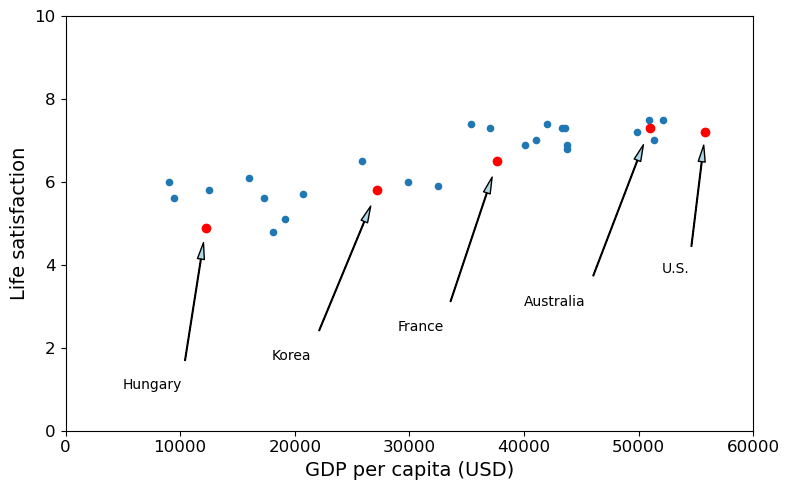

In [149]:
# ============================================================
# Create a scatter plot showing the relationship between
# GDP per capita and Life Satisfaction
# ============================================================

# ------------------------------------------------------------
# Step 1: Create the scatter plot
# ------------------------------------------------------------
#
# sample_data contains two columns:
#
# GDP per capita
# Life satisfaction
#
# Each row represents one country.
#
# A scatter plot displays one point per country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
#
# figsize=(8,5)
#
# controls the size of the figure:
#
# width  = 8 inches
# height = 5 inches
#
# Larger figures are easier to read.
# ------------------------------------------------------------
sample_data.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction',
    figsize=(8, 5)
)


# ------------------------------------------------------------
# Step 2: Set the visible range of the axes
# ------------------------------------------------------------
#
# plt.axis([xmin, xmax, ymin, ymax])
#
# Here:
#
# x-axis:
# from 0 to 60,000 USD
#
# y-axis:
# from 0 to 10
#
# This ensures that all countries fit nicely
# within the plot area.
#
# Without this command, Matplotlib would choose
# axis limits automatically.
# ------------------------------------------------------------
plt.axis([0, 60000, 0, 10])


# ------------------------------------------------------------
# Step 3: Define custom positions for text labels
# ------------------------------------------------------------
#
# We want to label several countries on the graph.
#
# The dictionary below specifies where each text
# label should be placed.
#
# Format:
#
# "Country Name": (x_position, y_position)
#
# These coordinates determine where the label text
# appears, NOT where the actual country data point is.
#
# The label positions are manually chosen to avoid
# overlapping text.
# ------------------------------------------------------------
position_text = {
    "Hungary": (5000, 1),
    "Korea": (18000, 1.7),
    "France": (29000, 2.4),
    "Australia": (40000, 3.0),
    "United States": (52000, 3.8),
}


# ------------------------------------------------------------
# Step 4: Add annotations for selected countries
# ------------------------------------------------------------
#
# .items() allows us to loop through all entries
# in the dictionary.
#
# Example:
#
# country  -> "Hungary"
# pos_text -> (5000, 1)
#
# The loop repeats for every country in the dictionary.
# ------------------------------------------------------------
for country, pos_text in position_text.items():

    # --------------------------------------------------------
    # Retrieve the actual data coordinates for the country
    # --------------------------------------------------------
    #
    # sample_data.loc[country]
    #
    # loc selects a row using the country name.
    #
    # Example:
    #
    # Hungary
    # GDP per capita     12240
    # Life satisfaction   4.9
    #
    # The two values are stored in:
    #
    # pos_data_x
    # pos_data_y
    # --------------------------------------------------------
    pos_data_x, pos_data_y = sample_data.loc[country]

    
    # --------------------------------------------------------
    # Shorten "United States" to "U.S."
    # --------------------------------------------------------
    #
    # This is done only to make the graph cleaner
    # and reduce label length.
    # --------------------------------------------------------
    country = (
        "U.S."
        if country == "United States"
        else country
    )

    
    # --------------------------------------------------------
    # Add a text label with an arrow
    # --------------------------------------------------------
    #
    # plt.annotate() places text on a graph.
    #
    # Parameters:
    #
    # country
    #     Text to display.
    #
    # xy=(...)
    #     Actual data point location.
    #
    # xytext=(...)
    #     Location of the label text.
    #
    # arrowprops
    #     Controls the appearance of the arrow.
    #
    # The arrow points from the label text
    # to the actual country data point.
    # --------------------------------------------------------
    plt.annotate(
        country,
        xy=(pos_data_x, pos_data_y),
        xytext=pos_text,
        arrowprops=dict(
            facecolor='lightblue',
            width=0.5,
            shrink=0.1,
            headwidth=5
        )
    )

    
    # --------------------------------------------------------
    # Highlight the selected country using a red dot
    # --------------------------------------------------------
    #
    # "ro" means:
    #
    # r = red
    # o = circle marker
    #
    # This makes the annotated countries
    # easier to spot on the graph.
    # --------------------------------------------------------
    plt.plot(
        pos_data_x,
        pos_data_y,
        "ro"
    )


# ------------------------------------------------------------
# Step 5: Add a label to the x-axis
# ------------------------------------------------------------
#
# This text appears below the horizontal axis.
#
# It tells the reader that GDP is measured
# in US dollars.
# ------------------------------------------------------------
plt.xlabel("GDP per capita (USD)")


# ------------------------------------------------------------
# Step 6: Save the figure to disk
# ------------------------------------------------------------
#
# save_fig() is a custom function defined earlier.
#
# The figure will be saved inside:
#
# images/fundamentals/
#
# with the filename:
#
# money_happy_scatterplot.png
# ------------------------------------------------------------
save_fig('money_happy_scatterplot')


# ------------------------------------------------------------
# Step 7: Display the figure on screen
# ------------------------------------------------------------
#
# Without plt.show(), the figure may not appear
# in some Python environments.
#
# This command renders the final plot.
# ------------------------------------------------------------
plt.show()

In [150]:
sample_data.to_csv(os.path.join("datasets", "lifesat", "lifesat.csv"))

In [151]:
sample_data.loc[list(position_text.keys())]

,GDP per capita,Life satisfaction
Country,,
Hungary,12239.894,4.9
Korea,27195.197,5.8
France,37675.006,6.5
Australia,50961.865,7.3
United States,55805.204,7.2


Saving figure tweaking_model_params_plot


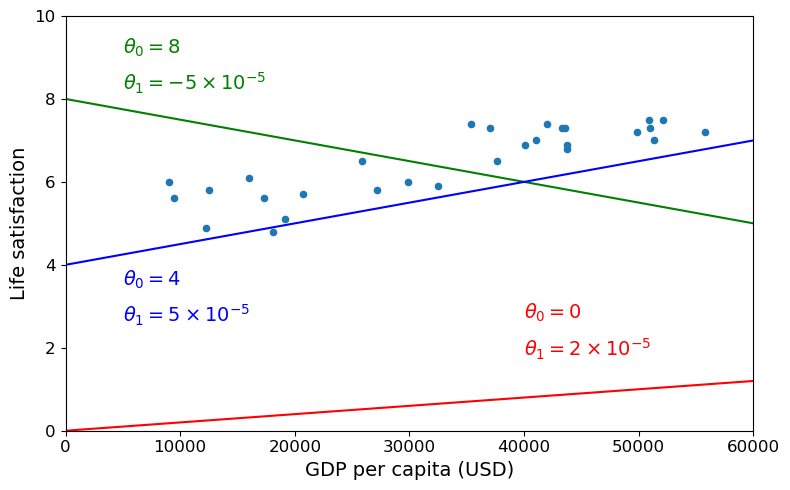

In [152]:
# ============================================================
# Visualizing Different Linear Regression Models
# ============================================================
#
# In this example, we draw several possible straight lines
# on top of the GDP vs Life Satisfaction data.
#
# The purpose is to understand how changing the model
# parameters affects the prediction line.
#
# A Linear Regression model can be written as:
#
# Life Satisfaction = θ₀ + θ₁ × GDP per capita
#
# where:
#
# θ₀ (theta_0)
#     Intercept
#     The value of the line when GDP = 0
#
# θ₁ (theta_1)
#     Slope
#     Controls how steeply the line rises or falls
#
# We will manually create three different lines
# using different values of θ₀ and θ₁.
# ============================================================


# ------------------------------------------------------------
# Import NumPy
# ------------------------------------------------------------
#
# NumPy provides tools for numerical computations.
#
# We will use it to generate many x-values
# for drawing smooth lines.
# ------------------------------------------------------------
import numpy as np


# ------------------------------------------------------------
# Step 1: Plot the original data points
# ------------------------------------------------------------
#
# Each point represents one country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
# ------------------------------------------------------------
sample_data.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction',
    figsize=(8, 5)
)


# ------------------------------------------------------------
# Step 2: Label the x-axis
# ------------------------------------------------------------
#
# This text appears below the horizontal axis.
# ------------------------------------------------------------
plt.xlabel("GDP per capita (USD)")


# ------------------------------------------------------------
# Step 3: Set the visible axis range
# ------------------------------------------------------------
#
# x-axis:
# from 0 to 60,000 USD
#
# y-axis:
# from 0 to 10
#
# This keeps all points and lines visible.
# ------------------------------------------------------------
plt.axis([0, 60000, 0, 10])


# ------------------------------------------------------------
# Step 4: Create x-values for drawing lines
# ------------------------------------------------------------
#
# np.linspace(start, stop, number_of_points)
#
# creates evenly spaced values between:
#
# 0 and 60,000
#
# Here:
#
# start = 0
# stop  = 60000
# points = 1000
#
# Result:
#
# X = [0, 60, 120, 180, ... , 60000]
#
# Using many points produces smooth lines.
# ------------------------------------------------------------
X = np.linspace(0, 60000, 1000)


# ============================================================
# First Model (Red Line)
# ============================================================
#
# θ₀ = 0
# θ₁ = 2 × 10⁻⁵
#
# Equation:
#
# y = 0 + (2 × 10⁻⁵) × x
#
# This line starts at zero and increases slowly.
# ------------------------------------------------------------
plt.plot(
    X,
    2 * X / 100000,
    "r"          # r = red line
)

# Display θ₀ value on the graph
plt.text(
    40000,
    2.7,
    r"$\theta_0 = 0$",
    fontsize=14,
    color="r"
)

# Display θ₁ value on the graph
plt.text(
    40000,
    1.8,
    r"$\theta_1 = 2 \times 10^{-5}$",
    fontsize=14,
    color="r"
)


# ============================================================
# Second Model (Green Line)
# ============================================================
#
# θ₀ = 8
# θ₁ = -5 × 10⁻⁵
#
# Equation:
#
# y = 8 - (5 × 10⁻⁵)x
#
# This line slopes downward.
#
# As GDP increases,
# predicted life satisfaction decreases.
#
# This clearly does not match the data well.
# ------------------------------------------------------------
plt.plot(
    X,
    8 - 5 * X / 100000,
    "g"          # g = green line
)

# Display θ₀ value
plt.text(
    5000,
    9.1,
    r"$\theta_0 = 8$",
    fontsize=14,
    color="g"
)

# Display θ₁ value
plt.text(
    5000,
    8.2,
    r"$\theta_1 = -5 \times 10^{-5}$",
    fontsize=14,
    color="g"
)


# ============================================================
# Third Model (Blue Line)
# ============================================================
#
# θ₀ = 4
# θ₁ = 5 × 10⁻⁵
#
# Equation:
#
# y = 4 + (5 × 10⁻⁵)x
#
# This line starts at 4 and rises upward.
#
# It follows the data points much better than
# the previous two examples.
# ------------------------------------------------------------
plt.plot(
    X,
    4 + 5 * X / 100000,
    "b"          # b = blue line
)

# Display θ₀ value
plt.text(
    5000,
    3.5,
    r"$\theta_0 = 4$",
    fontsize=14,
    color="b"
)

# Display θ₁ value
plt.text(
    5000,
    2.6,
    r"$\theta_1 = 5 \times 10^{-5}$",
    fontsize=14,
    color="b"
)


# ------------------------------------------------------------
# Step 5: Save the figure
# ------------------------------------------------------------
#
# The custom save_fig() function stores the graph as:
#
# images/fundamentals/tweaking_model_params_plot.png
# ------------------------------------------------------------
save_fig('tweaking_model_params_plot')


# ------------------------------------------------------------
# Step 6: Display the final graph
# ------------------------------------------------------------
#
# This renders the completed figure.
# ------------------------------------------------------------
plt.show()

In [153]:
# ============================================================
# Train a Linear Regression Model and Extract Its Parameters
# ============================================================
#
# The goal of this code is to:
#
# 1. Create a Linear Regression model.
# 2. Train the model using the sample data.
# 3. Learn the best-fitting straight line.
# 4. Extract the model parameters:
#
#    θ₀ (theta_0) = intercept
#    θ₁ (theta_1) = slope
#
# Recall that a Linear Regression model has the form:
#
# Life Satisfaction = θ₀ + θ₁ × GDP per capita
#
# The machine learning algorithm automatically finds
# the values of θ₀ and θ₁ that best fit the data.
# ============================================================


# ------------------------------------------------------------
# Step 1: Import the Linear Regression module
# ------------------------------------------------------------
#
# Scikit-Learn provides many machine learning models.
#
# Here we import the linear_model module,
# which contains Linear Regression.
# ------------------------------------------------------------
from sklearn import linear_model


# ------------------------------------------------------------
# Step 2: Create a Linear Regression model
# ------------------------------------------------------------
#
# This creates an empty model.
#
# At this point:
#
# - The model has not seen any data.
# - No learning has occurred yet.
# - θ₀ and θ₁ are still unknown.
#
# Think of this as creating a blank student
# before teaching them anything.
# ------------------------------------------------------------
lin1 = linear_model.LinearRegression()


# ------------------------------------------------------------
# Step 3: Prepare the input feature matrix X
# ------------------------------------------------------------
#
# We want GDP per capita to be the input feature.
#
# Example:
#
# GDP per capita
# ----------------
# 12240
# 35678
# 48765
#
# Scikit-Learn expects input data to be stored
# as a two-dimensional matrix:
#
# [[12240],
#  [35678],
#  [48765]]
#
# np.c_ converts the column into the required format.
# ------------------------------------------------------------
Xsample = np.c_[
    sample_data["GDP per capita"]
]


# ------------------------------------------------------------
# Step 4: Prepare the target variable y
# ------------------------------------------------------------
#
# This is the value we want the model to predict.
#
# Example:
#
# Life satisfaction
# -----------------
# 4.9
# 6.8
# 7.3
#
# Again, np.c_ converts the values into
# a two-dimensional structure expected
# by Scikit-Learn.
# ------------------------------------------------------------
ysample = np.c_[
    sample_data["Life satisfaction"]
]


# ------------------------------------------------------------
# Step 5: Train (fit) the model
# ------------------------------------------------------------
#
# fit(X, y)
#
# teaches the model using the training data.
#
# During training, the algorithm:
#
# - Examines GDP values
# - Examines Life Satisfaction values
# - Searches for the straight line that best
#   fits the data points
#
# After training, the model learns:
#
# θ₀ = intercept
# θ₁ = slope
#
# These parameters define the final prediction line.
# ------------------------------------------------------------
lin1.fit(
    Xsample,
    ysample
)


# ------------------------------------------------------------
# Step 6: Extract the learned intercept (θ₀)
# ------------------------------------------------------------
#
# intercept_
#
# stores the value where the regression line
# crosses the y-axis.
#
# In other words:
#
# Predicted Life Satisfaction when
# GDP per capita = 0
#
# [0] is used because Scikit-Learn stores
# the result inside an array.
# ------------------------------------------------------------
t0 = lin1.intercept_[0]


# ------------------------------------------------------------
# Step 7: Extract the learned slope (θ₁)
# ------------------------------------------------------------
#
# coef_
#
# stores the slope of the regression line.
#
# This tells us:
#
# How much Life Satisfaction changes when
# GDP per capita increases.
#
# [0][0] accesses the numerical value
# from the coefficient matrix.
# ------------------------------------------------------------
t1 = lin1.coef_[0][0]


# ------------------------------------------------------------
# Step 8: Display the learned parameters
# ------------------------------------------------------------
#
# The output will be something like:
#
# (4.85, 4.91e-05)
#
# meaning:
#
# θ₀ = 4.85
# θ₁ = 0.0000491
#
# Therefore the learned equation becomes:
#
# Life Satisfaction
# =
# 4.85 + 0.0000491 × GDP per capita
#
# This is the line that best fits
# the training data.
# ------------------------------------------------------------
t0, t1

(4.853052800266435, 4.911544589158485e-05)

Saving figure best_fit_model_plot


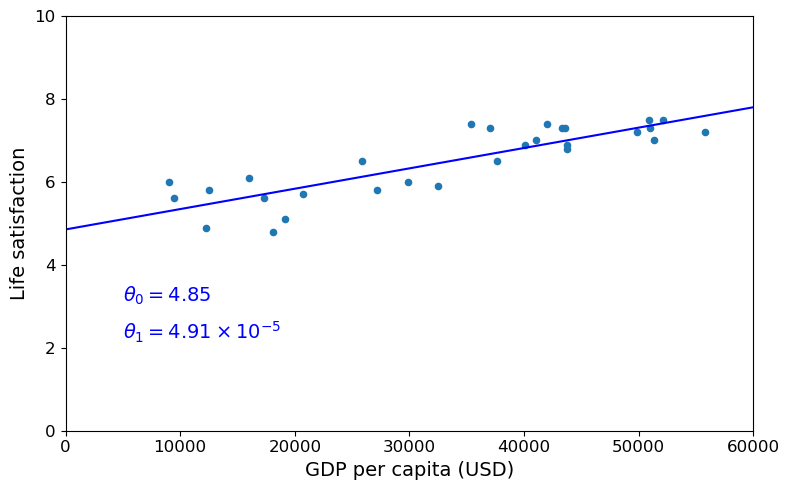

In [154]:
# ============================================================
# Visualizing the Best-Fit Linear Regression Model
# ============================================================
#
# In the previous cell, the Linear Regression algorithm
# automatically learned the best values for:
#
# θ₀ (theta_0) = intercept
# θ₁ (theta_1) = slope
#
# The learned equation has the form:
#
# Life Satisfaction = θ₀ + θ₁ × GDP per capita
#
# In this cell, we visualize that learned equation
# together with the original country data.
#
# The goal is to see how well the regression line
# fits the observed data points.
# ============================================================


# ------------------------------------------------------------
# Step 1: Create a scatter plot of the original data
# ------------------------------------------------------------
#
# Each dot represents one country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
#
# figsize=(8,5)
# controls the size of the figure.
# ------------------------------------------------------------
sample_data.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction',
    figsize=(8, 5)
)


# ------------------------------------------------------------
# Step 2: Add a label to the x-axis
# ------------------------------------------------------------
#
# This label appears below the horizontal axis.
#
# USD stands for United States Dollars.
# ------------------------------------------------------------
plt.xlabel("GDP per capita (USD)")


# ------------------------------------------------------------
# Step 3: Set the visible range of the graph
# ------------------------------------------------------------
#
# plt.axis([xmin, xmax, ymin, ymax])
#
# x-axis:
# 0 to 60,000 USD
#
# y-axis:
# 0 to 10
#
# This ensures all data points and the regression
# line are clearly visible.
# ------------------------------------------------------------
plt.axis([0, 60000, 0, 10])


# ------------------------------------------------------------
# Step 4: Generate many GDP values
# ------------------------------------------------------------
#
# np.linspace(start, stop, num_points)
#
# creates 1000 equally spaced values between:
#
# 0 and 60,000
#
# Example:
#
# [0, 60, 120, 180, ..., 60000]
#
# These values will be used to draw a smooth
# regression line.
# ------------------------------------------------------------
X = np.linspace(0, 60000, 1000)


# ------------------------------------------------------------
# Step 5: Draw the learned regression line
# ------------------------------------------------------------
#
# The regression equation is:
#
# y = θ₀ + θ₁ × x
#
# where:
#
# θ₀ = t0
# θ₁ = t1
#
# These values were learned automatically
# during training.
#
# For every GDP value in X,
# the model computes a predicted
# Life Satisfaction value.
#
# The resulting points form a straight line.
#
# "b" means:
#
# b = blue
# ------------------------------------------------------------
plt.plot(
    X,
    t0 + t1 * X,
    "b"
)


# ------------------------------------------------------------
# Step 6: Display the learned intercept (θ₀)
# ------------------------------------------------------------
#
# plt.text(x, y, text)
#
# places text at a specific position
# inside the graph.
#
# Here we display the value of θ₀
# next to the regression line.
#
# θ₀ = 4.85
#
# This means:
#
# If GDP per capita were zero,
# the model would predict a life
# satisfaction score of approximately 4.85.
# ------------------------------------------------------------
plt.text(
    5000,
    3.1,
    r"$\theta_0 = 4.85$",
    fontsize=14,
    color="b"
)


# ------------------------------------------------------------
# Step 7: Display the learned slope (θ₁)
# ------------------------------------------------------------
#
# θ₁ controls how steep the line is.
#
# θ₁ = 4.91 × 10⁻⁵
#
# This means:
#
# As GDP per capita increases,
# predicted Life Satisfaction also increases.
#
# The positive slope indicates a positive
# relationship between wealth and happiness.
# ------------------------------------------------------------
plt.text(
    5000,
    2.2,
    r"$\theta_1 = 4.91 \times 10^{-5}$",
    fontsize=14,
    color="b"
)


# ------------------------------------------------------------
# Step 8: Save the figure
# ------------------------------------------------------------
#
# save_fig() is a custom function
# defined earlier.
#
# The figure will be saved as:
#
# images/fundamentals/best_fit_model_plot.png
# ------------------------------------------------------------
save_fig('best_fit_model_plot')


# ------------------------------------------------------------
# Step 9: Display the figure
# ------------------------------------------------------------
#
# This renders the completed graph.
# ------------------------------------------------------------
plt.show()

In [155]:
# ============================================================
# Predict the Life Satisfaction of Cyprus
# ============================================================
#
# In previous cells:
#
# 1. We loaded the GDP dataset.
# 2. We trained a Linear Regression model.
# 3. The model learned the relationship between:
#
#    GDP per capita
#          and
#    Life Satisfaction
#
# Now we will use the trained model to predict
# the Life Satisfaction score of Cyprus.
#
# This is an example of making a prediction on
# a country that was not included in the training data.
# ============================================================


# ------------------------------------------------------------
# Step 1: Retrieve Cyprus' GDP per capita
# ------------------------------------------------------------
#
# gdp_per_capita is a DataFrame where:
#
# Rows    -> Countries
# Columns -> Economic indicators
#
# Example:
#
# Country
# Germany
# France
# Cyprus
#
# loc["Cyprus"]
#
# selects the row corresponding to Cyprus.
#
# Then:
#
# ["GDP per capita"]
#
# selects the GDP per capita value from that row.
#
# The result is a single numerical value.
#
# Example:
#
# 22587
#
# (actual value depends on the dataset)
# ------------------------------------------------------------
cyprus_gdp_per_capita = gdp_per_capita.loc[
    "Cyprus"
]["GDP per capita"]


# ------------------------------------------------------------
# Step 2: Display Cyprus' GDP per capita
# ------------------------------------------------------------
#
# print()
#
# outputs the value to the screen so we can verify
# that it was retrieved correctly.
#
# Example output:
#
# 22587
# ------------------------------------------------------------
print(cyprus_gdp_per_capita)


# ------------------------------------------------------------
# Step 3: Use the trained model to make a prediction
# ------------------------------------------------------------
#
# predict()
#
# asks the trained Linear Regression model
# to estimate Life Satisfaction.
#
# Scikit-Learn expects the input to be a
# two-dimensional array.
#
# Therefore:
#
# [[cyprus_gdp_per_capita]]
#
# is used instead of:
#
# cyprus_gdp_per_capita
#
# Example:
#
# [[22587]]
#
# The model then substitutes this value into
# the learned equation:
#
# Life Satisfaction
# =
# θ₀ + θ₁ × GDP per capita
#
# and computes a prediction.
# ------------------------------------------------------------
cyprus_predicted_life_satisfaction = lin1.predict(
    [[cyprus_gdp_per_capita]]
)[0][0]


# ------------------------------------------------------------
# Why [0][0] ?
# ------------------------------------------------------------
#
# predict() returns a nested array.
#
# Example:
#
# [[5.96]]
#
# The first [0]
# selects the first row.
#
# Result:
#
# [5.96]
#
# The second [0]
# selects the first value.
#
# Result:
#
# 5.96
#
# This leaves us with a simple number
# instead of an array.
# ------------------------------------------------------------


# ------------------------------------------------------------
# Step 4: Display the predicted Life Satisfaction
# ------------------------------------------------------------
#
# The output will be something like:
#
# 5.96242338
#
# Interpretation:
#
# According to the Linear Regression model,
# a country with Cyprus' GDP per capita
# is expected to have a Life Satisfaction
# score of approximately 5.96.
# ------------------------------------------------------------
cyprus_predicted_life_satisfaction

22587.49


5.962447443188149

Saving figure cyprus_prediction_plot


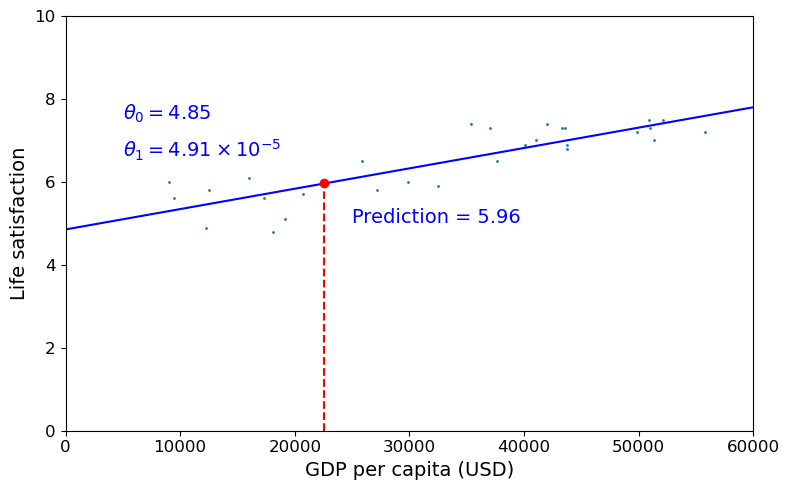

In [157]:
# ============================================================
# Visualizing the Prediction for Cyprus
# ============================================================
#
# In previous cells:
#
# 1. We trained a Linear Regression model.
# 2. We learned the best-fit line:
#
#    Life Satisfaction = θ₀ + θ₁ × GDP per capita
#
# 3. We predicted the Life Satisfaction score
#    for Cyprus.
#
# This cell creates a visualization showing:
#
# ✓ The original country data
# ✓ The learned regression line
# ✓ Cyprus' GDP per capita
# ✓ The model's prediction for Cyprus
#
# This makes it easier to understand how the
# prediction is obtained.
# ============================================================


# ------------------------------------------------------------
# Step 1: Plot the original country data
# ------------------------------------------------------------
#
# Each dot represents one country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life Satisfaction
#
# figsize=(5,3)
#
# creates a figure that is:
# 5 inches wide
# 3 inches tall
#
# s=1
#
# makes the scatter points very small.
#
# This helps reduce clutter in the figure.
# ------------------------------------------------------------
sample_data.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction',
    figsize=(8, 5),
    s=1
)


# ------------------------------------------------------------
# Step 2: Add a label to the x-axis
# ------------------------------------------------------------
#
# This text appears below the horizontal axis.
#
# USD = United States Dollar
# ------------------------------------------------------------
plt.xlabel("GDP per capita (USD)")


# ------------------------------------------------------------
# Step 3: Generate many GDP values
# ------------------------------------------------------------
#
# np.linspace(start, stop, num_points)
#
# creates 1000 evenly spaced values between:
#
# 0 and 60,000
#
# These values will be used to draw
# a smooth regression line.
# ------------------------------------------------------------
X = np.linspace(
    0,
    60000,
    1000
)


# ------------------------------------------------------------
# Step 4: Draw the learned regression line
# ------------------------------------------------------------
#
# The model learned:
#
# Life Satisfaction
# =
# θ₀ + θ₁ × GDP per capita
#
# where:
#
# θ₀ = t0
# θ₁ = t1
#
# For every GDP value in X,
# the corresponding predicted Life Satisfaction
# value is calculated.
#
# "b" means:
#
# b = blue line
# ------------------------------------------------------------
plt.plot(
    X,
    t0 + t1 * X,
    "b"
)


# ------------------------------------------------------------
# Step 5: Define the visible plotting area
# ------------------------------------------------------------
#
# plt.axis([xmin, xmax, ymin, ymax])
#
# x-axis:
# 0 to 60,000 USD
#
# y-axis:
# 0 to 10
#
# This ensures all data points,
# annotations, and prediction markers
# remain visible.
# ------------------------------------------------------------
plt.axis([0, 60000, 0, 10])


# ------------------------------------------------------------
# Step 6: Display the learned intercept θ₀
# ------------------------------------------------------------
#
# θ₀ represents the intercept of the line.
#
# In this model:
#
# θ₀ ≈ 4.85
#
# This means:
#
# If GDP per capita were zero,
# the model would predict a Life Satisfaction
# value of approximately 4.85.
# ------------------------------------------------------------
plt.text(
    5000,
    7.5,
    r"$\theta_0 = 4.85$",
    fontsize=14,
    color="b"
)


# ------------------------------------------------------------
# Step 7: Display the learned slope θ₁
# ------------------------------------------------------------
#
# θ₁ determines how steep the line is.
#
# In this model:
#
# θ₁ ≈ 4.91 × 10⁻⁵
#
# Since θ₁ is positive,
# higher GDP values generally lead to
# higher predicted Life Satisfaction.
# ------------------------------------------------------------
plt.text(
    5000,
    6.6,
    r"$\theta_1 = 4.91 \times 10^{-5}$",
    fontsize=14,
    color="b"
)


# ------------------------------------------------------------
# Step 8: Draw a vertical line for Cyprus
# ------------------------------------------------------------
#
# cyprus_gdp_per_capita
#
# contains Cyprus' GDP value.
#
# The first point:
#
# (Cyprus GDP, 0)
#
# is located at the bottom of the graph.
#
# The second point:
#
# (Cyprus GDP, Predicted Life Satisfaction)
#
# lies on the regression line.
#
# Connecting these two points creates
# a vertical dashed line.
#
# "r--" means:
#
# r  = red
# -- = dashed line
#
# This visually shows how Cyprus'
# GDP value maps to the predicted
# Life Satisfaction value.
# ------------------------------------------------------------
plt.plot(
    [cyprus_gdp_per_capita,
     cyprus_gdp_per_capita],

    [0,
     cyprus_predicted_life_satisfaction],

    "r--"
)


# ------------------------------------------------------------
# Step 9: Display the prediction value
# ------------------------------------------------------------
#
# The text:
#
# "Prediction = 5.96"
#
# is added to the graph to indicate
# the model's estimated Life Satisfaction
# score for Cyprus.
# ------------------------------------------------------------
plt.text(
    25000,
    5.0,
    r"Prediction = 5.96",
    fontsize=14,
    color="b"
)


# ------------------------------------------------------------
# Step 10: Mark the prediction point
# ------------------------------------------------------------
#
# The point:
#
# (
#   Cyprus GDP,
#   Predicted Life Satisfaction
# )
#
# is plotted as a red circle.
#
# "ro" means:
#
# r = red
# o = circular marker
#
# This point represents the exact prediction
# produced by the Linear Regression model.
# ------------------------------------------------------------
plt.plot(
    cyprus_gdp_per_capita,
    cyprus_predicted_life_satisfaction,
    "ro"
)


# ------------------------------------------------------------
# Step 11: Save the figure
# ------------------------------------------------------------
#
# The custom save_fig() function saves
# the current figure as:
#
# images/fundamentals/cyprus_prediction_plot.png
# ------------------------------------------------------------
save_fig('cyprus_prediction_plot')


# ------------------------------------------------------------
# Step 12: Display the completed figure
# ------------------------------------------------------------
#
# plt.show() renders the final graph.
#
# The graph now shows:
#
# ✓ Original country data
# ✓ Best-fit regression line
# ✓ Cyprus GDP value
# ✓ Predicted Life Satisfaction
#
# This provides a visual explanation of how
# the machine learning model makes predictions.
# ------------------------------------------------------------
plt.show()

In [130]:
sample_data[7:10]

,GDP per capita,Life satisfaction
Country,,
Portugal,19121.592,5.1
Slovenia,20732.482,5.7
Spain,25864.721,6.5


In [131]:
(5.1+5.7+6.5)/3

5.766666666666667

In [158]:
# ============================================================
# Create a backup of the original datasets
# ============================================================
#
# Before modifying the datasets, we store copies of the
# original DataFrames.
#
# This is useful because many Pandas operations below use:
#
# inplace=True
#
# which permanently changes the DataFrame.
#
# If something goes wrong later, we can restore the original
# data using:
#
# oecd_bli, gdp_per_capita = backup
#
# Think of this as creating a "save point" before editing.
# ============================================================
backup = oecd_bli, gdp_per_capita


# ============================================================
# Function: prepare_country_stats()
# ============================================================
#
# Purpose:
#
# This function takes two raw datasets:
#
# 1. OECD Better Life Index dataset
# 2. GDP per capita dataset
#
# and transforms them into a clean dataset suitable for
# machine learning.
#
# The function performs:
#
# ✓ Data filtering
# ✓ Data reshaping
# ✓ Data merging
# ✓ Sorting
# ✓ Removal of selected countries
#
# Finally, it returns a clean DataFrame containing only:
#
# GDP per capita
# Life satisfaction
#
# ============================================================
def prepare_country_stats(oecd_bli, gdp_per_capita):

    # --------------------------------------------------------
    # Step 1: Keep only total-population statistics
    # --------------------------------------------------------
    #
    # The OECD dataset contains data for different groups:
    #
    # TOT  = Total population
    # MEN  = Men
    # WOMEN = Women
    #
    # We only want country-wide averages,
    # therefore we keep rows where:
    #
    # INEQUALITY == "TOT"
    # --------------------------------------------------------
    oecd_bli = oecd_bli[
        oecd_bli["INEQUALITY"] == "TOT"
    ]


    # --------------------------------------------------------
    # Step 2: Reshape the OECD dataset
    # --------------------------------------------------------
    #
    # Original format:
    #
    # Country    Indicator            Value
    # Germany    Income              31252
    # Germany    Life satisfaction    6.8
    #
    # Desired format:
    #
    # Country    Income   Life satisfaction
    # Germany    31252          6.8
    #
    # After pivoting:
    #
    # Rows    -> Countries
    # Columns -> Indicators
    # Values  -> Indicator values
    # --------------------------------------------------------
    oecd_bli = oecd_bli.pivot(
        index="Country",
        columns="Indicator",
        values="Value"
    )


    # --------------------------------------------------------
    # Step 3: Rename the GDP column
    # --------------------------------------------------------
    #
    # Original column name:
    #
    # "2015"
    #
    # New column name:
    #
    # "GDP per capita"
    #
    # This makes the meaning much clearer.
    #
    # inplace=True modifies the DataFrame directly.
    # --------------------------------------------------------
    gdp_per_capita.rename(
        columns={"2015": "GDP per capita"},
        inplace=True
    )


    # --------------------------------------------------------
    # Step 4: Use country names as row labels
    # --------------------------------------------------------
    #
    # Before:
    #
    # 0
    # 1
    # 2
    #
    # After:
    #
    # Germany
    # France
    # Canada
    #
    # This allows countries to be matched
    # between datasets.
    # --------------------------------------------------------
    gdp_per_capita.set_index(
        "Country",
        inplace=True
    )


    # --------------------------------------------------------
    # Step 5: Merge the two datasets
    # --------------------------------------------------------
    #
    # We now combine:
    #
    # OECD statistics
    # +
    # GDP statistics
    #
    # pd.merge() joins the tables using country names.
    #
    # left_index=True
    # right_index=True
    #
    # tells Pandas:
    #
    # Match rows based on the row index
    # (country names).
    #
    # Example:
    #
    # Germany
    #
    # OECD data  + GDP data
    #
    # become one row.
    # --------------------------------------------------------
    full_country_stats = pd.merge(
        left=oecd_bli,
        right=gdp_per_capita,
        left_index=True,
        right_index=True
    )


    # --------------------------------------------------------
    # Step 6: Sort countries by GDP per capita
    # --------------------------------------------------------
    #
    # Countries will be ordered from:
    #
    # Lowest GDP
    #        to
    # Highest GDP
    #
    # This makes later analysis easier.
    #
    # inplace=True modifies the DataFrame directly.
    # --------------------------------------------------------
    full_country_stats.sort_values(
        by="GDP per capita",
        inplace=True
    )


    # --------------------------------------------------------
    # Step 7: Select countries to remove
    # --------------------------------------------------------
    #
    # These row positions are intentionally removed
    # by the author.
    #
    # The removed countries will later be used
    # for illustration and prediction examples.
    # --------------------------------------------------------
    remove_indices = [
        0, 1, 6, 8, 33, 34, 35
    ]


    # --------------------------------------------------------
    # Step 8: Determine which rows to keep
    # --------------------------------------------------------
    #
    # range(36)
    #
    # creates:
    #
    # 0, 1, 2, ..., 35
    #
    # representing all 36 countries.
    #
    # We subtract the removed rows.
    #
    # Result:
    #
    # A list containing only the countries
    # that will remain in the training dataset.
    # --------------------------------------------------------
    keep_indices = list(
        set(range(36))
        - set(remove_indices)
    )


    # --------------------------------------------------------
    # Step 9: Return the final cleaned dataset
    # --------------------------------------------------------
    #
    # We keep only two columns:
    #
    # GDP per capita
    # Life satisfaction
    #
    # Then:
    #
    # .iloc[keep_indices]
    #
    # selects only the rows we decided to keep.
    #
    # The resulting DataFrame becomes the final
    # machine-learning dataset used throughout
    # Chapter 1.
    #
    # Example:
    #
    # Country      GDP per capita   Life satisfaction
    # Australia        50961               7.3
    # Austria          43724               6.9
    # ...
    # --------------------------------------------------------
    return full_country_stats[
        ["GDP per capita", "Life satisfaction"]
    ].iloc[keep_indices]

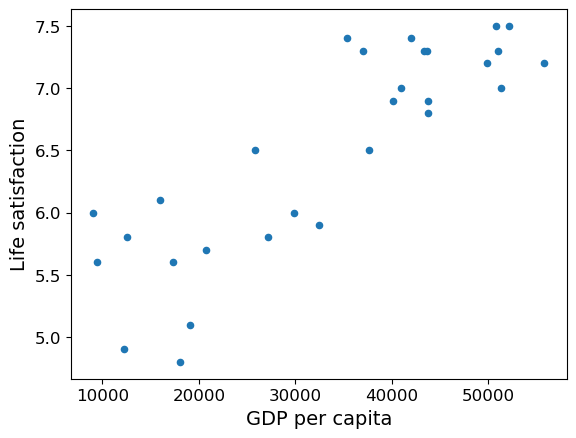

[[5.96242338]]


In [159]:
# ============================================================
# Complete Machine Learning Workflow:
# Predicting Life Satisfaction from GDP per Capita
# ============================================================
#
# This cell performs the entire machine learning pipeline:
#
# 1. Import required libraries
# 2. Load the datasets
# 3. Clean and prepare the data
# 4. Visualize the data
# 5. Create a Linear Regression model
# 6. Train the model
# 7. Make a prediction for Cyprus
#
# The goal is to learn the relationship between:
#
# GDP per capita
#          and
# Life Satisfaction
#
# and then use that relationship to make predictions.
# ============================================================


# ------------------------------------------------------------
# Step 1: Import required libraries
# ------------------------------------------------------------

# Matplotlib is used to create plots and visualizations.
import matplotlib.pyplot as plt

# NumPy is used for numerical computations and arrays.
import numpy as np

# Pandas is used to load, organize, and manipulate datasets.
import pandas as pd

# Scikit-Learn contains machine learning algorithms.
# Here we will use Linear Regression.
import sklearn.linear_model


# ------------------------------------------------------------
# Step 2: Load the OECD dataset
# ------------------------------------------------------------
#
# pd.read_csv() reads a CSV file and stores the data
# in a Pandas DataFrame.
#
# thousands=','
#
# tells Pandas that commas are thousand separators.
#
# Example:
#
# "12,345"
#
# is interpreted as:
#
# 12345
# ------------------------------------------------------------
oecd_bli = pd.read_csv(
    datapath + "oecd_bli_2015.csv",
    thousands=','
)


# ------------------------------------------------------------
# Step 3: Load the GDP dataset
# ------------------------------------------------------------
#
# This dataset uses a slightly different format.
#
# delimiter='\t'
#     Columns are separated by TAB characters.
#
# encoding='latin1'
#     Character encoding used by the file.
#
# na_values="n/a"
#     Treats "n/a" as missing data.
# ------------------------------------------------------------
gdp_per_capita = pd.read_csv(
    datapath + "gdp_per_capita.csv",
    thousands=',',
    delimiter='\t',
    encoding='latin1',
    na_values="n/a"
)


# ------------------------------------------------------------
# Step 4: Prepare the data
# ------------------------------------------------------------
#
# prepare_country_stats() is a custom function
# defined earlier.
#
# It:
#
# ✓ Cleans the datasets
# ✓ Merges them
# ✓ Sorts countries
# ✓ Removes selected countries
#
# and returns a clean dataset containing:
#
# GDP per capita
# Life satisfaction
# ------------------------------------------------------------
country_stats = prepare_country_stats(
    oecd_bli,
    gdp_per_capita
)


# ------------------------------------------------------------
# Step 5: Create the input feature matrix (X)
# ------------------------------------------------------------
#
# Machine learning models require input features.
#
# In this example:
#
# GDP per capita
#
# is the only feature.
#
# np.c_ converts the column into a 2D structure
# required by Scikit-Learn.
#
# Example:
#
# [[12000],
#  [25000],
#  [50000]]
# ------------------------------------------------------------
X = np.c_[
    country_stats["GDP per capita"]
]


# ------------------------------------------------------------
# Step 6: Create the target variable (y)
# ------------------------------------------------------------
#
# This is the value we want the model to predict.
#
# In this example:
#
# Life satisfaction
#
# Example:
#
# [[5.1],
#  [6.3],
#  [7.8]]
# ------------------------------------------------------------
y = np.c_[
    country_stats["Life satisfaction"]
]


# ------------------------------------------------------------
# Step 7: Visualize the data
# ------------------------------------------------------------
#
# Create a scatter plot.
#
# Each point represents one country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
#
# This allows us to visually inspect whether
# a relationship exists between the variables.
# ------------------------------------------------------------
country_stats.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction'
)


# ------------------------------------------------------------
# Display the plot
# ------------------------------------------------------------
plt.show()


# ------------------------------------------------------------
# Step 8: Create a Linear Regression model
# ------------------------------------------------------------
#
# Linear Regression tries to find the straight line
# that best fits the observed data.
#
# The model has the form:
#
# Life Satisfaction
# =
# θ₀ + θ₁ × GDP per capita
#
# where:
#
# θ₀ = intercept
# θ₁ = slope
#
# At this stage:
#
# ✓ The model exists
# ✗ It has not learned anything yet
# ------------------------------------------------------------
model = sklearn.linear_model.LinearRegression()


# ------------------------------------------------------------
# Step 9: Train the model
# ------------------------------------------------------------
#
# fit(X, y)
#
# teaches the model using the training data.
#
# During training, the algorithm:
#
# - Examines GDP values
# - Examines Life Satisfaction values
# - Finds the line that best fits the data
#
# After training:
#
# The model learns θ₀ and θ₁.
# ------------------------------------------------------------
model.fit(
    X,
    y
)


# ------------------------------------------------------------
# Step 10: Create a new input value
# ------------------------------------------------------------
#
# We now want to predict the Life Satisfaction
# of Cyprus.
#
# Cyprus' GDP per capita:
#
# 22,587 USD
#
# Scikit-Learn requires a 2D array,
# therefore:
#
# [[22587]]
#
# is used instead of:
#
# 22587
# ------------------------------------------------------------
X_new = [[22587]]


# ------------------------------------------------------------
# Step 11: Make a prediction
# ------------------------------------------------------------
#
# predict()
#
# uses the learned regression equation
# to estimate Life Satisfaction.
#
# Internally, the model computes:
#
# θ₀ + θ₁ × 22587
#
# and returns the result.
# ------------------------------------------------------------
prediction = model.predict(X_new)


# ------------------------------------------------------------
# Step 12: Display the prediction
# ------------------------------------------------------------
#
# Example output:
#
# [[5.96242338]]
#
# Interpretation:
#
# According to the trained model,
# a country with a GDP per capita of
# 22,587 USD is expected to have a
# Life Satisfaction score of about 5.96.
# ------------------------------------------------------------
print(prediction)

In [160]:
oecd_bli, gdp_per_capita = backup

In [161]:
missing_data

,GDP per capita,Life satisfaction
Country,,
Brazil,8669.998,7.0
Mexico,9009.280,6.7
Chile,13340.905,6.7
Czech Republic,17256.918,6.5
Norway,74822.106,7.4
Switzerland,80675.308,7.5
Luxembourg,101994.093,6.9


In [162]:
position_text2 = {
    "Brazil": (1000, 9.0),
    "Mexico": (11000, 9.0),
    "Chile": (25000, 9.0),
    "Czech Republic": (35000, 9.0),
    "Norway": (60000, 3),
    "Switzerland": (72000, 3.0),
    "Luxembourg": (90000, 3.0),
}

Saving figure representative_training_data_scatterplot


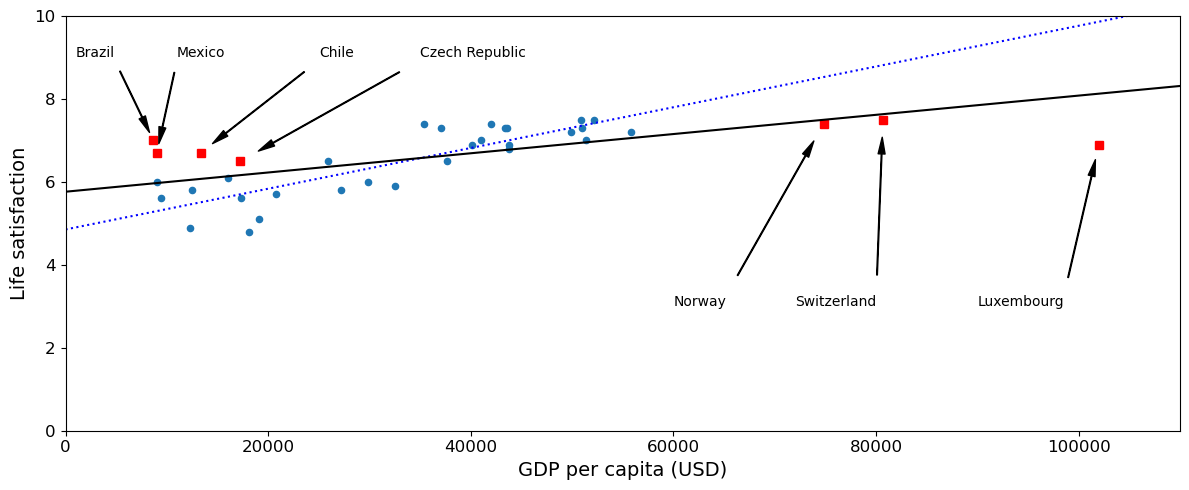

In [164]:
# ============================================================
# Compare the Original Training Data with Missing Countries
# ============================================================
#
# This cell visualizes an important machine learning idea:
#
# The choice of training data affects the model.
#
# We compare:
#
# 1. A model trained only on sample_data
# 2. A model trained on the full dataset
#
# The goal is to show that removing or adding countries
# can change the learned regression line.
# ============================================================


# ------------------------------------------------------------
# Step 1: Plot the sample training data
# ------------------------------------------------------------
#
# sample_data contains the countries kept for training.
#
# Each point represents one country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
#
# figsize=(8,3)
# creates a wide but short figure.
# ------------------------------------------------------------
sample_data.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction',
    figsize=(12, 5)
)


# ------------------------------------------------------------
# Step 2: Set the visible graph area
# ------------------------------------------------------------
#
# x-axis:
# 0 to 110,000 USD
#
# y-axis:
# 0 to 10
#
# The x-axis is larger here because some removed countries
# have very high GDP per capita.
# ------------------------------------------------------------
plt.axis([0, 110000, 0, 10])


# ------------------------------------------------------------
# Step 3: Add labels for the missing countries
# ------------------------------------------------------------
#
# position_text2 is a dictionary defined earlier.
#
# It contains:
#
# country name -> position of label text
#
# Example:
#
# "Luxembourg": (60000, 9)
#
# The loop adds labels and arrows for each missing country.
# ------------------------------------------------------------
for country, pos_text in position_text2.items():

    # --------------------------------------------------------
    # Get the real GDP and Life Satisfaction values
    # for the current missing country.
    #
    # missing_data.loc[country]
    #
    # selects the row using the country name.
    # --------------------------------------------------------
    pos_data_x, pos_data_y = missing_data.loc[country]

    # --------------------------------------------------------
    # Add the country name as text with an arrow.
    #
    # xy:
    #   actual data point location
    #
    # xytext:
    #   label text location
    #
    # arrowprops:
    #   controls arrow style
    # --------------------------------------------------------
    plt.annotate(
        country,
        xy=(pos_data_x, pos_data_y),
        xytext=pos_text,
        arrowprops=dict(
            facecolor='black',
            width=0.5,
            shrink=0.1,
            headwidth=5
        )
    )

    # --------------------------------------------------------
    # Plot the missing country as a red square.
    #
    # "rs" means:
    #
    # r = red
    # s = square marker
    #
    # This visually separates missing countries
    # from the normal sample data.
    # --------------------------------------------------------
    plt.plot(
        pos_data_x,
        pos_data_y,
        "rs"
    )


# ------------------------------------------------------------
# Step 4: Create x-values for drawing model lines
# ------------------------------------------------------------
#
# These values are used to draw smooth regression lines
# across the full x-axis range.
# ------------------------------------------------------------
X = np.linspace(
    0,
    110000,
    1000
)


# ------------------------------------------------------------
# Step 5: Plot the model trained only on sample_data
# ------------------------------------------------------------
#
# t0 and t1 were learned earlier from sample_data.
#
# This line shows the model trained after removing
# selected countries.
#
# "b:" means:
#
# b = blue
# : = dotted line
# ------------------------------------------------------------
plt.plot(
    X,
    t0 + t1 * X,
    "b:"
)


# ------------------------------------------------------------
# Step 6: Create a new Linear Regression model
# ------------------------------------------------------------
#
# This model will be trained on the full dataset,
# including the countries that were previously removed.
# ------------------------------------------------------------
lin_reg_full = linear_model.LinearRegression()


# ------------------------------------------------------------
# Step 7: Prepare input data from the full dataset
# ------------------------------------------------------------
#
# Xfull contains GDP per capita values for all countries.
#
# np.c_ converts the column into the 2D format
# required by Scikit-Learn.
# ------------------------------------------------------------
Xfull = np.c_[
    full_country_stats["GDP per capita"]
]


# ------------------------------------------------------------
# Step 8: Prepare target data from the full dataset
# ------------------------------------------------------------
#
# yfull contains Life Satisfaction values
# for all countries.
# ------------------------------------------------------------
yfull = np.c_[
    full_country_stats["Life satisfaction"]
]


# ------------------------------------------------------------
# Step 9: Train the model on the full dataset
# ------------------------------------------------------------
#
# This time, the model learns from all available countries,
# not only the reduced sample.
# ------------------------------------------------------------
lin_reg_full.fit(
    Xfull,
    yfull
)


# ------------------------------------------------------------
# Step 10: Extract the full-data model parameters
# ------------------------------------------------------------
#
# t0full:
#   intercept learned from the full dataset
#
# t1full:
#   slope learned from the full dataset
#
# These parameters define the regression line
# trained with all countries included.
# ------------------------------------------------------------
t0full = lin_reg_full.intercept_[0]
t1full = lin_reg_full.coef_[0][0]


# ------------------------------------------------------------
# Step 11: Generate x-values again
# ------------------------------------------------------------
#
# This repeats the same x-range used above.
#
# It is not strictly necessary because X already exists,
# but it keeps the code explicit and clear.
# ------------------------------------------------------------
X = np.linspace(
    0,
    110000,
    1000
)


# ------------------------------------------------------------
# Step 12: Plot the model trained on the full dataset
# ------------------------------------------------------------
#
# This black line represents the regression model
# trained using all countries.
#
# "k" means black in Matplotlib.
# ------------------------------------------------------------
plt.plot(
    X,
    t0full + t1full * X,
    "k"
)


# ------------------------------------------------------------
# Step 13: Add x-axis label
# ------------------------------------------------------------
#
# This label tells the reader that GDP per capita
# is measured in US dollars.
# ------------------------------------------------------------
plt.xlabel("GDP per capita (USD)")


# ------------------------------------------------------------
# Step 14: Save the figure
# ------------------------------------------------------------
#
# The figure will be saved as:
#
# images/fundamentals/representative_training_data_scatterplot.png
# ------------------------------------------------------------
save_fig('representative_training_data_scatterplot')


# ------------------------------------------------------------
# Step 15: Display the final plot
# ------------------------------------------------------------
#
# The plot shows:
#
# ✓ Sample training countries
# ✓ Missing countries
# ✓ Regression line from sample data
# ✓ Regression line from full data
# ------------------------------------------------------------
plt.show()

Saving figure overfitting_model_plot


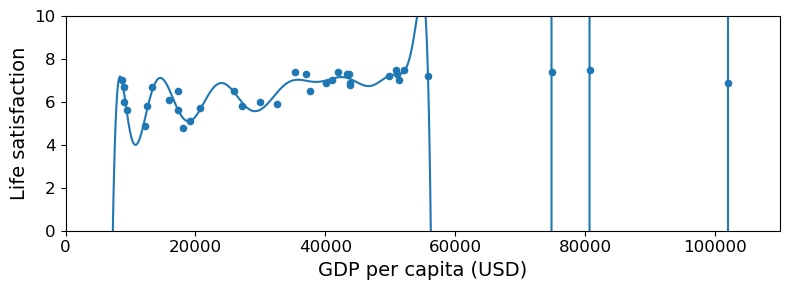

In [167]:
# ============================================================
# Example of Overfitting using Polynomial Regression
# ============================================================
#
# In previous examples, we used Linear Regression.
#
# Linear Regression learns a straight-line relationship:
#
# Life Satisfaction
# =
# θ₀ + θ₁ × GDP per capita
#
# However, sometimes we create models that are too complex.
#
# Such models may fit the training data extremely well,
# but perform poorly on new unseen data.
#
# This problem is called:
#
# OVERFITTING
#
# In this example, we intentionally create a highly complex
# polynomial model (degree = 30) to demonstrate overfitting.
# ============================================================


# ------------------------------------------------------------
# Step 1: Plot the full dataset
# ------------------------------------------------------------
#
# full_country_stats contains all available countries.
#
# Each point represents one country.
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
#
# figsize=(8,3)
#
# creates a wide figure suitable for comparing curves.
# ------------------------------------------------------------
full_country_stats.plot(
    kind='scatter',
    x="GDP per capita",
    y='Life satisfaction',
    figsize=(8, 3)
)


# ------------------------------------------------------------
# Step 2: Set the visible plotting area
# ------------------------------------------------------------
#
# x-axis:
# 0 to 110,000 USD
#
# y-axis:
# 0 to 10
#
# This ensures that all countries and the learned curve
# remain visible.
# ------------------------------------------------------------
plt.axis([0, 110000, 0, 10])


# ------------------------------------------------------------
# Step 3: Import preprocessing tools
# ------------------------------------------------------------
#
# preprocessing
#
# contains tools for transforming data before it is
# passed into a machine learning model.
#
# pipeline
#
# allows multiple processing steps to be combined into
# one reusable workflow.
# ------------------------------------------------------------
from sklearn import preprocessing
from sklearn import pipeline


# ------------------------------------------------------------
# Step 4: Create polynomial features
# ------------------------------------------------------------
#
# PolynomialFeatures transforms one input variable into
# many polynomial terms.
#
# Original feature:
#
# x
#
# Degree 2:
#
# x, x²
#
# Degree 3:
#
# x, x², x³
#
# Degree 30:
#
# x, x², x³, ..., x³⁰
#
# This allows the model to learn extremely complex curves
# instead of simple straight lines.
#
# include_bias=False
#
# prevents Scikit-Learn from automatically adding
# a constant column of ones.
# ------------------------------------------------------------
poly = preprocessing.PolynomialFeatures(
    degree=30,
    include_bias=False
)


# ------------------------------------------------------------
# Step 5: Create a StandardScaler
# ------------------------------------------------------------
#
# High-degree polynomial features can become extremely large.
#
# Example:
#
# 50,000²
# 50,000³
# ...
# 50,000³⁰
#
# Such huge values can cause numerical instability.
#
# StandardScaler rescales all features so they have:
#
# Mean ≈ 0
# Standard Deviation ≈ 1
#
# This helps the learning algorithm work properly.
# ------------------------------------------------------------
scaler = preprocessing.StandardScaler()


# ------------------------------------------------------------
# Step 6: Create a Linear Regression model
# ------------------------------------------------------------
#
# Even though we are building a polynomial model,
# the final learning algorithm is still Linear Regression.
#
# Why?
#
# Because after generating polynomial features,
# the model remains linear with respect to its parameters.
#
# Example:
#
# y =
# θ₀ + θ₁x + θ₂x² + θ₃x³ + ...
# ------------------------------------------------------------
lin_reg2 = linear_model.LinearRegression()


# ------------------------------------------------------------
# Step 7: Build a machine learning pipeline
# ------------------------------------------------------------
#
# A Pipeline executes multiple processing steps
# automatically in sequence.
#
# Step 1:
# Create polynomial features
#
# Step 2:
# Scale the features
#
# Step 3:
# Train Linear Regression
#
# The names:
#
# 'poly'
# 'scal'
# 'lin'
#
# are simply labels for each stage.
# ------------------------------------------------------------
pipeline_reg = pipeline.Pipeline([
    ('poly', poly),
    ('scal', scaler),
    ('lin', lin_reg2)
])


# ------------------------------------------------------------
# Step 8: Train the pipeline
# ------------------------------------------------------------
#
# Xfull:
# GDP per capita values
#
# yfull:
# Life Satisfaction values
#
# During training:
#
# 1. Polynomial features are created.
# 2. Features are scaled.
# 3. Linear Regression learns the coefficients.
#
# All of this happens automatically.
# ------------------------------------------------------------
pipeline_reg.fit(
    Xfull,
    yfull
)


# ------------------------------------------------------------
# Step 9: Predict values along the entire GDP range
# ------------------------------------------------------------
#
# X contains 1000 GDP values between:
#
# 0 and 110,000
#
# X[:, np.newaxis]
#
# converts the 1D array:
#
# [1, 2, 3]
#
# into:
#
# [[1],
#  [2],
#  [3]]
#
# which is the format expected by Scikit-Learn.
#
# predict()
#
# computes the Life Satisfaction value
# for every GDP value in X.
# ------------------------------------------------------------
curve = pipeline_reg.predict(
    X[:, np.newaxis]
)


# ------------------------------------------------------------
# Step 10: Draw the learned polynomial curve
# ------------------------------------------------------------
#
# Unlike Linear Regression,
# which produces a straight line,
#
# this model produces a highly flexible curve.
#
# Because degree=30 is extremely large,
# the curve may bend dramatically
# to follow the training data.
#
# This is a classic example of overfitting.
# ------------------------------------------------------------
plt.plot(
    X,
    curve
)


# ------------------------------------------------------------
# Step 11: Label the x-axis
# ------------------------------------------------------------
#
# This label appears below the horizontal axis.
# ------------------------------------------------------------
plt.xlabel("GDP per capita (USD)")


# ------------------------------------------------------------
# Step 12: Save the figure
# ------------------------------------------------------------
#
# The figure will be saved as:
#
# images/fundamentals/overfitting_model_plot.png
# ------------------------------------------------------------
save_fig('overfitting_model_plot')


# ------------------------------------------------------------
# Step 13: Display the figure
# ------------------------------------------------------------
#
# This renders the completed plot.
#
# The graph now shows:
#
# ✓ Original country data
# ✓ Highly complex polynomial curve
#
# The curve demonstrates how a model can become
# overly sensitive to the training data.
# ------------------------------------------------------------
plt.show()

In [169]:
# ============================================================
# Find Countries Whose Names Contain the Letter "W"
# ============================================================
#
# This cell demonstrates several useful Pandas concepts:
#
# 1. Accessing row labels (country names)
# 2. Filtering data using a condition
# 3. Using list comprehensions
# 4. Selecting specific columns
#
# The goal is:
#
# Find all countries whose names contain the letter:
#
# "W"
#
# and then display their Life Satisfaction values.
# ============================================================


# ------------------------------------------------------------
# Step 1: Access all country names
# ------------------------------------------------------------
#
# full_country_stats is a DataFrame where:
#
# Rows    -> Countries
# Columns -> Statistics
#
# Example:
#
# Country
# --------
# Australia
# Austria
# Belgium
# Canada
# ...
#
# full_country_stats.index
#
# returns all row labels (country names).
#
# Example:
#
# Index([
#     'Australia',
#     'Austria',
#     'Belgium',
#     ...
# ])
# ------------------------------------------------------------


# ------------------------------------------------------------
# Step 2: Create a filtered list of country names
# ------------------------------------------------------------
#
# This is called a LIST COMPREHENSION.
#
# General structure:
#
# [item for item in collection if condition]
#
# It means:
#
# "Loop through all items and keep only those
# that satisfy the condition."
#
# Here:
#
# c
#   represents a country name
#
# full_country_stats.index
#   contains all country names
#
# c.upper()
#
# converts the country name to uppercase.
#
# Example:
#
# "Sweden"
#     ↓
# "SWEDEN"
#
# Why?
#
# To ensure the search is not affected
# by uppercase/lowercase differences.
#
# Then:
#
# "W" in c.upper()
#
# checks whether the letter W appears
# anywhere in the country name.
#
# Examples:
#
# "SWEDEN"      → True
# "NEW ZEALAND" → True
# "GERMANY"     → False
#
# The resulting list contains only countries
# whose names include the letter W.
# ------------------------------------------------------------
[
    c
    for c in full_country_stats.index
    if "W" in c.upper()
]


# ------------------------------------------------------------
# Step 3: Select only those countries
# ------------------------------------------------------------
#
# .loc[]
#
# selects rows using row labels
# (country names).
#
# Example:
#
# full_country_stats.loc[
#     ["Sweden", "New Zealand"]
# ]
#
# would return only those rows.
#
# Here, the list comprehension created above
# is used directly inside .loc[].
# ------------------------------------------------------------


# ------------------------------------------------------------
# Step 4: Select only the Life Satisfaction column
# ------------------------------------------------------------
#
# After selecting the matching countries,
# we extract only:
#
# "Life satisfaction"
#
# from the DataFrame.
#
# The result is a Pandas Series.
#
# Example:
#
# Sweden         7.2
# New Zealand    7.3
#
# (Actual values depend on the dataset.)
# ------------------------------------------------------------
full_country_stats.loc[
    [
        c
        for c in full_country_stats.index
        if "W" in c.upper()
    ]
]["Life satisfaction"]

Country
New Zealand    7.3
Sweden         7.2
Norway         7.4
Switzerland    7.5
Name: Life satisfaction, dtype: float64

In [140]:
gdp_per_capita.loc[[c for c in gdp_per_capita.index if "W" in c.upper()]].head()

,Subject Descriptor,Units,Scale,Country/Series-specific Notes,GDP per capita,Estimates Start After
Country,,,,,,
Botswana,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",6040.957,2008.0
Kuwait,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",29363.027,2014.0
Malawi,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",354.275,2011.0
New Zealand,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",37044.891,2015.0
Norway,"Gross domestic product per capita, current prices",U.S. dollars,Units,"See notes for: Gross domestic product, curren...",74822.106,2015.0


Saving figure ridge_model_plot


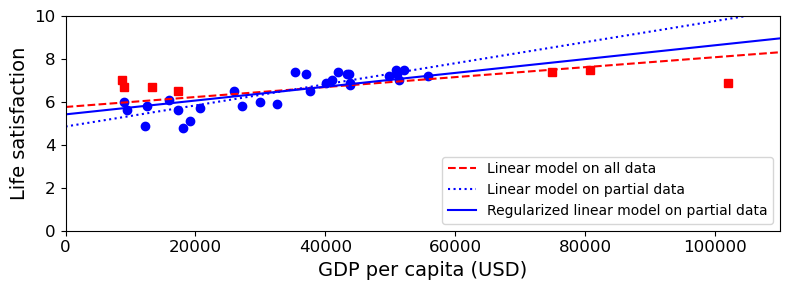

In [170]:
# ============================================================
# Comparing Three Different Linear Models
# ============================================================
#
# This cell compares three machine learning models:
#
# 1. Linear Regression trained on ALL countries
# 2. Linear Regression trained on PARTIAL data
# 3. Ridge Regression trained on PARTIAL data
#
# The goal is to demonstrate:
#
# ✓ Effect of missing training data
# ✓ Effect of regularization
# ✓ Differences between learned regression lines
#
# This is an important concept in machine learning because
# models trained on different data or with different
# assumptions may produce different predictions.
# ============================================================


# ------------------------------------------------------------
# Step 1: Create a new figure
# ------------------------------------------------------------
#
# plt.figure()
#
# creates an empty plotting area.
#
# figsize=(8,3)
#
# Width  = 8 inches
# Height = 3 inches
#
# A wide figure is useful for comparing multiple models.
# ------------------------------------------------------------
plt.figure(figsize=(8,3))


# ------------------------------------------------------------
# Step 2: Label the axes
# ------------------------------------------------------------
#
# x-axis:
# GDP per capita
#
# y-axis:
# Life satisfaction
#
# These labels help readers understand
# what the graph represents.
# ------------------------------------------------------------
plt.xlabel("GDP per capita")
plt.ylabel('Life satisfaction')


# ------------------------------------------------------------
# Step 3: Plot countries used for training
# ------------------------------------------------------------
#
# sample_data contains the countries that were kept
# in the reduced dataset.
#
# list(...)
#
# converts the Pandas columns into standard Python lists.
#
# "bo" means:
#
# b = blue
# o = circle marker
#
# Therefore:
#
# Blue circles = training countries.
# ------------------------------------------------------------
plt.plot(
    list(sample_data["GDP per capita"]),
    list(sample_data["Life satisfaction"]),
    "bo"
)


# ------------------------------------------------------------
# Step 4: Plot countries that were removed
# ------------------------------------------------------------
#
# missing_data contains countries intentionally excluded
# from the reduced dataset.
#
# "rs" means:
#
# r = red
# s = square marker
#
# Therefore:
#
# Red squares = excluded countries.
# ------------------------------------------------------------
plt.plot(
    list(missing_data["GDP per capita"]),
    list(missing_data["Life satisfaction"]),
    "rs"
)


# ------------------------------------------------------------
# Step 5: Generate GDP values for drawing smooth lines
# ------------------------------------------------------------
#
# np.linspace(start, stop, num_points)
#
# creates 1000 evenly spaced GDP values between:
#
# 0 and 110,000
#
# These values will be used to draw the regression lines.
# ------------------------------------------------------------
X = np.linspace(
    0,
    110000,
    1000
)


# ------------------------------------------------------------
# Step 6: Plot the model trained on ALL countries
# ------------------------------------------------------------
#
# t0full
#     intercept from the full dataset
#
# t1full
#     slope from the full dataset
#
# Equation:
#
# y = t0full + t1full × X
#
# "r--" means:
#
# r  = red
# -- = dashed line
#
# This line represents the model trained using
# every country available.
# ------------------------------------------------------------
plt.plot(
    X,
    t0full + t1full * X,
    "r--",
    label="Linear model on all data"
)


# ------------------------------------------------------------
# Step 7: Plot the model trained on partial data
# ------------------------------------------------------------
#
# t0 and t1 were learned earlier from sample_data.
#
# Equation:
#
# y = t0 + t1 × X
#
# "b:" means:
#
# b = blue
# : = dotted line
#
# This line shows how the model changes when
# several countries are removed.
# ------------------------------------------------------------
plt.plot(
    X,
    t0 + t1 * X,
    "b:",
    label="Linear model on partial data"
)


# ============================================================
# Ridge Regression (Regularized Linear Regression)
# ============================================================
#
# Ridge Regression is a modified version of
# Linear Regression.
#
# It introduces a penalty that discourages
# excessively large model parameters.
#
# Benefits:
#
# ✓ Reduces overfitting
# ✓ Produces more stable models
# ✓ Less sensitive to unusual data points
#
# In this example, we intentionally use a very
# strong regularization strength.
# ============================================================


# ------------------------------------------------------------
# Step 8: Create a Ridge Regression model
# ------------------------------------------------------------
#
# alpha controls the amount of regularization.
#
# Small alpha:
#     behaves similarly to Linear Regression
#
# Large alpha:
#     stronger penalty
#     flatter regression line
#
# Here:
#
# alpha = 10^9.5
#
# is extremely large.
#
# This is done purely for illustration.
# ------------------------------------------------------------
ridge = linear_model.Ridge(
    alpha=10**9.5
)


# ------------------------------------------------------------
# Step 9: Prepare the training data
# ------------------------------------------------------------
#
# Xsample:
# GDP values
#
# ysample:
# Life Satisfaction values
#
# np.c_ converts the columns into the
# two-dimensional format expected by Scikit-Learn.
# ------------------------------------------------------------
Xsample = np.c_[
    sample_data["GDP per capita"]
]

ysample = np.c_[
    sample_data["Life satisfaction"]
]


# ------------------------------------------------------------
# Step 10: Train the Ridge model
# ------------------------------------------------------------
#
# fit()
#
# learns the best values for:
#
# intercept
# slope
#
# while also applying the regularization penalty.
# ------------------------------------------------------------
ridge.fit(
    Xsample,
    ysample
)


# ------------------------------------------------------------
# Step 11: Extract the learned parameters
# ------------------------------------------------------------
#
# t0ridge:
#     Ridge intercept
#
# t1ridge:
#     Ridge slope
#
# Notice:
#
# Ridge often learns a smaller slope than
# ordinary Linear Regression because
# regularization discourages large coefficients.
# ------------------------------------------------------------
t0ridge = ridge.intercept_[0]
t1ridge = ridge.coef_[0]


# ------------------------------------------------------------
# Step 12: Plot the Ridge Regression line
# ------------------------------------------------------------
#
# Equation:
#
# y = t0ridge + t1ridge × X
#
# "b" means:
#
# solid blue line
#
# This allows us to compare:
#
# - Ordinary Linear Regression
# - Regularized Linear Regression
# ------------------------------------------------------------
plt.plot(
    X,
    t0ridge + t1ridge * X,
    "b",
    label="Regularized linear model on partial data"
)


# ------------------------------------------------------------
# Step 13: Display a legend
# ------------------------------------------------------------
#
# A legend explains what each line represents.
#
# loc="lower right"
#
# places the legend in the lower-right corner
# of the figure.
# ------------------------------------------------------------
plt.legend(
    loc="lower right"
)


# ------------------------------------------------------------
# Step 14: Define visible axis limits
# ------------------------------------------------------------
#
# x-axis:
# 0 to 110,000 USD
#
# y-axis:
# 0 to 10
#
# This ensures all points and lines remain visible.
# ------------------------------------------------------------
plt.axis([
    0,
    110000,
    0,
    10
])


# ------------------------------------------------------------
# Step 15: Add a more descriptive x-axis label
# ------------------------------------------------------------
#
# This label includes the measurement unit.
# ------------------------------------------------------------
plt.xlabel("GDP per capita (USD)")


# ------------------------------------------------------------
# Step 16: Save the figure
# ------------------------------------------------------------
#
# The figure will be stored as:
#
# images/fundamentals/ridge_model_plot.png
# ------------------------------------------------------------
save_fig('ridge_model_plot')


# ------------------------------------------------------------
# Step 17: Display the completed figure
# ------------------------------------------------------------
#
# The final graph shows:
#
# ✓ Blue circles  → training countries
# ✓ Red squares   → removed countries
# ✓ Red dashed    → model trained on all data
# ✓ Blue dotted   → model trained on partial data
# ✓ Blue solid    → Ridge Regression model
#
# This visualization demonstrates how:
#
# - Training data affects the model
# - Regularization affects the model
# ------------------------------------------------------------
plt.show()